In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / 'C' / 'evoca.h').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('EvoCA repo root not found')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'python'))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import evoca_paths
from evoca_py import EvoCA, import_run
from evoca_explore import build_sim, run_sim, EVO_METRICS
from dyn_analysis import dyn_report

WS = 'Activity-metrics'
SCANS = ROOT / 'Research' / WS / 'Scans'
_T0 = time.time()
print('repo root:', ROOT)

repo root: /private/tmp/evoca_food-cap-standard


# Activity-metrics: lab notebook

**Question.** What is the right measure of *adaptive* (as opposed to drift/turnover) evolutionary activity in EvoCA, and which configurations maximize it?

This is the chronological lab notebook of the workstream. Each section below takes one past episode (scan, campaign, or probe), says what was asked and done, shows one or more small **example runs** that illustrate the phenomenology with the activity probes (cumulative-activity waves, whole-genome activity versus its neutral shadow, `A_new`, fixed-space `eg`/`dyn` excess, per-bucket z-scores, effective-rule species counts), and records the observations. Anything labeled *observed in this example run* is a fresh N=96 (or smaller) run made while writing this notebook; it is **not** a campaign result.

Links: digests (unapproved drafts) [`digests/neutral-model-methodology.ipynb`](digests/neutral-model-methodology.ipynb) and [`digests/pure-evo-regime.ipynb`](digests/pure-evo-regime.ipynb); scans [`2026-04-27_evo_focus`](Scans/2026-04-27_evo_focus/notes.md), [`2026-05-16_causal_control`](Scans/2026-05-16_causal_control/), [`2026-05-17_causal_control_v2`](Scans/2026-05-17_causal_control_v2/notes.md), [`2026-05-17_pure_evo_joint`](Scans/2026-05-17_pure_evo_joint/notes.md), [`2026-05-17_pure_evo_lut_only`](Scans/2026-05-17_pure_evo_lut_only/notes.md); analysis [`2026-05-17_pure_evo_analysis.md`](Scans/2026-05-17_pure_evo_analysis.md). Campaign narrative: [`Docs/devlog/2026-05-17_research-campaigns.md`](../../Docs/devlog/2026-05-17_research-campaigns.md).

**Running the examples interactively.** After each example run there is a code cell of commented-out lines that open the same configuration in the interactive SDL window (`run_with_controls`, from `python/controls.py`). Uncomment and run it to watch the simulation; it is commented out so that *Run All* never blocks on a window. Only one EvoCA lattice exists at a time, so this replaces any simulation still alive in the kernel. **Eating rule.** Everything above the final section uses the **standard model**: the capped mouthful (`food_cap=1`, the A9 fix), under which a cell never eats more food than its site holds. The legacy uncapped rule (`food_cap=0`) let `m_scale x score > 25` overdraw the site, drive `F` negative and drain the next eater's private food. It is unphysical and not part of the model. Every scan of this workstream first ran under it, so the main thread reads the 2026-10-23 standard-model rescans (`Scans/2026-10-23_*_standard`: same configs and protocol, today's code). The recipes in `Runs/` record no `food_cap` and load capped. Recorded-versus-rescan comparisons for the findings that moved, and the example-run results that exist only under the legacy rule, are in the final section, "Legacy rule (`food_cap=0`)".

**Open questions and directions (snapshot).** The cell below displays `ISSUES.md` as it was when this notebook was last executed. `ISSUES.md` is the single source; edit it, not this snapshot.

In [2]:
display(Markdown((ROOT/'Research'/WS/'ISSUES.md').read_text()))

# Activity-metrics: issues and directions
_Updated 2026-10-23_

Workstream question: what is the right measure of adaptive (vs. drift/turnover) evolutionary activity in EvoCA, and which configurations maximize it? Evidence labeled "example run" below comes from `Activity-metrics.ipynb` (N=96, 3000 steps, one or two seeds; not campaign results). Since 2026-10-23 scan numbers come from the standard-model rescans (`Scans/2026-10-23_*_standard`, capped mouthful `food_cap=1`) and example runs are standard-rule; recorded legacy-rule numbers appear only where marked.

## Decisions needed (N)
- **ACT-D1**: Which readout is the primary activity objective for re-ranking the pure-evo scans (and for any new campaign's selection step)? Candidates are listed in `Docs/Oct2026/00-review-of-prompt1.md` section 7; the review's expectation was "A_new on eff-species, z-scored against the fixed-space shadow". First-look evidence from the example runs weakens that single-scalar plan:
  - `A_new` as merged compares whole-genome-keyed real activity with the LUT-only shadow, so it is blind in egene-evolving runs: in the EGENE_only arm it is 0 while `eg` excess is about +8 (notebook section 3, 2026-10-23; +9 to +21 under the legacy rule).
  - `eff_activity` (F1) with the population-union mask collapses nothing: union mask is 250/250 bits and eff species equal full-genome species in every evolving example run (sections 1, 2, 4), so "A_new on eff-species" currently equals "A_new on full genome".
  - Per-bucket z-scores (G2) are valid in both subsystems, exactly 0 under a freeze, but are bidirectional (hundreds of buckets at z below -60 plus a positive tail) and need an aggregation rule (count above z=3? tail mass?) with a calibrated false-positive rate.
  - **Options:** (a) one scalar, `A_new` after repairing it (ACT-Q1, ACT-Q2); (b) one scalar built from z-tail counts; (c) a **two-channel vector** (`dyn`, `eg`), each as per-component excess or z-tail count on the fixed-space shadows, with `mu_lut>0` and diversity guards, selected by ACT-D2. **Recommendation: (c) now, as the recorded #1 data already show the two channels trade off** (below); keep `A_new` and eff species as diagnostics until ACT-Q1/Q2 are resolved. Blocks: the re-ranking campaign (ACT-N1), H1.
- **ACT-D2**: Adopt Pareto selection (`~/Projects/conepareto`, report `Docs/Oct2026/05-cone-pareto-package.md`) for two-objective questions in this workstream? The `pure_evo_joint` candidates give a concrete case (2026-10-23, standard-model rescan, 291 candidates; the recorded 284 gave the same picture): top-5 by the 5-key composite and top-5 by `dyn_excess_pc_slope` share no config; the composite correlates 0.72 with `eg` and 0.37 with `dyn` excess (recorded 0.69, 0.41); `eg` winners have `tax_per_egene = 8e-4` and `food_inc = 0.018`, `dyn` winners have `tax_per_egene = 0`, `food_inc = 0.010`, `m_scale` 1.2-2.0 (notebook 4a). **Recommendation: yes, for (`dyn`, `eg`) selection, using a box or quantile-box region so a config strong in one channel and dead in the other is not admitted (the compensation weakness of the mean, review section 6); keep scalarization only for single-objective composites.** The other two-objective questions (activity vs. Φ from L1, activity vs. lineage net-return from D2, RD structure vs. activity) belong to Resource-driving, Lineage-co-evolution, and Reaction-diffusion respectively. Blocks: how ACT-N1 selects follow-up configs.
- **ACT-D3**: Change the `EVO_METRICS` default once D1 is settled? It currently contains legacy `excess_activity_slope` (invalid for egene-driven runs) and `unique_top_genomes` (Spearman -0.43 with `dyn` excess and -0.58 with the legacy excess among the joint candidates of the 2026-10-23 rescan; recorded -0.55, -0.68), so the mean mixes turnover with its opposite. W1-a (2026-10-15) keeps defaults unchanged. **Recommendation: leave unchanged until D1, then replace with the D1 readouts and keep the legacy set under an explicit name for comparability.** Blocks: nothing urgent; it keeps old and new rankings from silently mixing.

## Open questions
- **ACT-Q1**: Can `A_new` be made valid for egene-driven runs? The real side is keyed by the whole genome while `N` (Channon shadow) carries LUT bytes only (established finding, `Docs/devlog/2026-05-17_research-campaigns.md`). Observed: EGENE_only arm `A_new` = 0 (both seeds) with positive `eg` excess; a frozen-mutation control gives `A_new` = 1, not 0. Possible repairs: key both sides on the LUT only, or build a shadow in the eff key space, or define `A_new` on the fixed spaces (count of buckets above a shared z or activity threshold). Also unresolved: p90 vs p99 threshold (W1-b says keep p90 and record p99 alongside; I found no p99 key in `run_sim` on main, so that recording is not yet implemented).
- **ACT-Q2**: Does `eff_activity` (F1) ever collapse species? The union-mask key saturates (250/250 bits exercised) in every evolving example run, so eff species equal full-genome species. The F1 design note says the per-cell mask splits identical genomes by neighborhood history (3-10x more species). Is a windowed or recent-use union, or a per-cell mask with a coarser key, the intended coarsening? Test on runs where silent churn is known to dominate (the D1 `silent-churn` regime in `tests/notebooks/dyn-promote-demo.ipynb`).
- **ACT-Q3**: `eg_excess_pc` is an artifact when the real run has one egene key present: with the egene not mutating (`mu_egene = 0`, `mu_egenome = 0.03` as Negene slot growth) on the evo_focus base it reads about +1.5e4 per tick with one key populated (2026-10-23, standard rule), versus 8-65 in egene-evolving runs. 2026-10-23: the notebook used to call this configuration "the evo_focus base"; it is not, because the April driver's `mu_egenome` was the egene mutation rate. With `mu_egene = 0.03` the base has 203 keys present and an `eg` slope of 17. Per-component normalization (`sum G / D_G - sum N / D_N`) explodes when `D_G` is 1. Needs a guard or a reported `D_G`; same family as the `dyn_excess_pc` frozen-rich-substrate artifact.
- **ACT-Q4**: Is the "mu_lut optimum is conditional on egene" claim robust? (a) Scan #2 freezes the egene by zeroing `tax_per_egene` as well as the mutation rates, so #1 vs #2 confounds egene mutation with egene cost (the v2 controls keep `tax_per_egene = 8e-4` in all arms and do not). (b) Marginal mean `dyn_excess_pc_slope` by `mu_lut` is flat and non-monotone in both scans (2026-10-23 rescan: joint 23.6, 27.8, 29.9, 27.0, 24.1; LUT-only 29.6, 23.0, 28.1, 25.1, 24.5), so the claim lives in the composite's top ranks; there the rescan keeps it (joint top-5 `mu_lut` 0.01-0.06, LUT-only top-5 0.06-0.15). (c) Example runs at N=96 reverse the #1-vs-#2 `dyn` contrast (2026-10-23: joint 8.1-9.5 vs LUT-only 9.9-19.1). (d) 2026-10-23: under the standard rule the fully frozen winner environment survives with `tax_per_egene = 8e-4` (2/2 seeds at N=96; it went extinct only under the legacy rule), so a cost-matched frozen arm is now possible. Needs a matched-cost re-run with replicates (ACT-N1).
- **ACT-Q5**: Is `m_scale = 2.5` (the composite winner, at the grid ceiling) a property of the `eg` channel only? Marginal mean `dyn_excess_pc_slope` by `m_scale` (joint, 2026-10-23 rescan): 27.1, 30.6, 27.2, 25.6, 20.9 for 1.0-2.5 (recorded 26.7, 31.5, 26.3, 20.6, 14.5), so 2.5 is still the worst `dyn` value on average, by less. R1 (the `m_scale` bracket, owned by Resource-driving) should be re-read per channel.
- **ACT-Q6**: Whole-genome excess is not interpretable under freezes or egene evolution: negative (-17 at N=96, -33 and -68 in the v1/v2 rescans) in EGENE_only and not a null in a single-genome frozen control (cumulative `excess_pc` 4,684 from a 3% real/shadow difference on one component, 2026-10-23). Should `run_sim` emit a validity flag (egene or `mu_lut=0` conditions, extinct, `D<k`) next to every excess key so scans cannot rank on an invalid readout? Extinct runs print large meaningless constants (about -1.9e5 for `eg`, -1.2e5 for `dyn` in extinct N=96 runs, 2026-10-15, legacy rule).
- **ACT-Q7**: `dyn_report` (D1) verdict on the pure-evo winner is rule-sensitive and sits near its gate. 2026-10-23: under the standard rule it is `functional` (`dyn_eff` 70.4/500, gate 60), consistent with positive `dyn` excess and 100/500 buckets at z>3; the `silent-churn` label (`dyn_eff` 38) recorded on 2026-10-15 came from the legacy rule. The gates were tuned on `mu_lut=0.03` demo regimes. Recalibrate on pure-evo winners before using the verdict for selection, or drop the verdict from ranking and keep it as a diagnostic.
- **ACT-Q8**: Seed and scale sensitivity. Scans used one seed (`seed=0`); the 2026-10-15 legacy-rule example runs showed large seed spread (EGENE_only `eg` slope 9.0 vs 21.5 across two seeds at N=96). 2026-10-23, standard rule: the spread is small (8.2 vs 7.9), the `eg` synergy appears at N=96 / 3000 (JOINT 11.9 above EGENE_only 8.1), and in the v2 rescan it is 1.4x (63.2 vs 45.0; recorded 2.1x, 64.8 vs 31.0). Any re-ranking needs at least 3 seeds and a scale check.
- **ACT-Q9**: False-positive rate of the z-score test. Frozen arms give z=0 trivially; the rate of z>3 under neutral drift with mutation flux >0 (the case that matters) is untested. A selection-free run with mutation on (for example the shadow compared with a second independent shadow) would calibrate it.

- **ACT-Q10** (2026-10-23): Is the `dyn_excess_pc` frozen-rich-substrate artifact a legacy-rule phenomenon? In Lineage's #3c, arm A (`mu_lut = 0` on an evolved substrate) read `dyn_excess_pc_slope` +335 (arm mean) under the legacy rule; the standard-model rescan (`Lineage-co-evolution/Scans/2026-10-23_3c_coevolution_substrate_standard`) reads -1.3, with C at +3.6 and B (frozen GoL) no longer extinct (0/10; recorded 10/10). The degenerate-baseline argument (zero realized LUT flux) still holds, so the rule "interpret `dyn` only where `mu_lut > 0`" stays as a guard, but the recorded explosion is not evidence for it under the standard model. Needs a direct test: freeze an evolved substrate at `m_scale <= 1`, where both rules agree. Affects the `neutral-model-methodology` digest and project memory `dyn-shadow-frozen-rich-substrate`.

## Next directions
- **ACT-N1**: Re-run the pure-evo grid (joint and LUT-only, matched `tax_per_egene`) with the readouts now on main (`dyn`/`eg` excess, `A_new`, z-tail counts, eff species) and 3+ seeds, then rank under each candidate objective and under the ACT-D2 selection. Kind: campaign. Blockers: ACT-D1 (which readouts to record as primary), ACT-D2, and ACT-N2 for z-tail and diversity columns. Cost note: an N=96, 3000-step run with every probe takes about 1 s here, so 300 configs x 3 seeds at N=128 and 5000 steps is laptop-scale. Cross-ref checkpoint D1, G1, G2.
- **ACT-N2**: Promote the notebook-local `trace()` quantities into `run_sim`: z-tail counts and tail mass, number of `eg`/`dyn` buckets present, eff species count, a per-run validity flag (ACT-Q6), and an extinct mask. Kind: needs dev (touches `python/evoca_explore.py`, so outside this workstream's write scope; N to authorize). Cross-ref G2, F1.
- **ACT-N3**: H1, the adaptive-vs-drift program: lineage net-return (D2) plus `A_new`/z-tail plus a shadow-beating test on the section-B sweep, including the adaptive fraction `excess/raw` (B2). Kind: analysis. Unblocked by the 2026-10-15 merges of D2 and G1; coordinate with Lineage-co-evolution (D2/D3) and Resource-driving (B1/B2, L1). Cross-ref checkpoint H1.
- **ACT-N4**: Repair or replace `A_new` and `eff_activity` per ACT-Q1/ACT-Q2 (keying both sides consistently; a coarsening that actually collapses silent churn). Kind: needs dev (C and python). Blocker: ACT-D1 (only worth doing if the scalar route is chosen). Cross-ref G1, F1.
- **ACT-N5**: Long-run (>= 50k ticks) at a pure-evo winner to characterize absolute (not just differential) behavior of the excess metrics; listed as step 4 of `Scans/2026-05-17_pure_evo_analysis.md`. Kind: campaign; N=128 is enough to start.
- **ACT-N6**: Calibration study for the z-score aggregate (ACT-Q9) and the diversity guards (ACT-Q3). Kind: analysis, then dev. Needed before z-tail counts are used as an objective.
- **ACT-N7**: Reaction-diffusion cross-check: the 04-27 balanced and evo-focused winners were picked on the legacy composite, the legacy rule and an older eating model; re-rank them under the D1 objective (the RD-robustness #4 inputs came from those). 2026-10-23: both inputs now have standard-model rescans (`Reaction-diffusion/Scans/2026-10-23_rescan_0427_standard`, `Scans/2026-10-23_evo_focus_standard`); in the evo_focus rescan the recorded winner, cfg 232, ranks 50th of 250 even under the legacy composite. Kind: analysis; coordinate with Reaction-diffusion.

## Parked
- Per-gene open-space (LUT-hash) neutral shadow with zero-fill (checkpoint G3): decided against (changes the estimand; pooled shadow is the correct estimator there).
- evo_focus "Scan 5" (push `mu_lut` to 0.10-0.20, `m_scale` to 2.0+) and N=512 validation of the 04-27 top configs: obsolete under the corrected-metric finding that the 04-27 optimum was a metric artifact. 2026-10-23: the standard-model rescan moves the evo_focus top-5 itself to `mu_lut` 0.003-0.01 (one of the top-25 at 0.06; recorded 12).
- Per-config reproducibility fix for pooled workers: done (`set_seed`, S1); the 2026-04-27 scans remain non-reproducible per config, only in distribution.
- Recipe `Runs/2026-04-27_high_excess_activity_slope.evoca` is a copy of `push_edges` cfg 98 (descriptor `top_9_cfg98_score0.78`), not a high-excess-slope winner; rename or re-describe when convenient (low priority).


## Tools used by the example runs

Everything below goes through public entry points: `import_run` (recipes in `Runs/`), `build_sim` and `run_sim` (the scan harness), `dyn_report` (D1), and the getters on `EvoCA`. `trace()` is a notebook-local sampler that records, at each sample: whole-genome cumulative activity `G` and its LUT-only Channon shadow `N`; `A_new` (G1) with the p90 shadow threshold, built exactly as `run_sim` builds it (checked for exact agreement against `run_sim` in section 4); fixed-space `eg`/`dyn` excess; how many `eg`/`dyn` buckets are populated; effective-rule (`eff`, F1) versus full-genome species counts; and the final per-bucket z-scores (G2). All runs set the C seed and the initial `v` field explicitly, so the notebook is reproducible. Example runs use N=96 and at most 3000 steps; the recorded scans used N=128 to 256 and 3000 to 15000 steps, so *levels* differ and only qualitative comparisons are made.

In [3]:
# load_recipe: import_run() a recipe, then make the run reproducible
# (import_run seeds neither the C PRNG nor the v field).
from evoca_nb import load_recipe, argb_to_rgb, slope   # shared notebook helpers: python/evoca_nb.py


def trace(sim, n_steps=3000, every=100, neutral=True):
    """Sample every activity readout on a live sim (frees it at the end).

    Per sample: whole-genome cumulative activity (G) and its LUT-only Channon
    shadow (N); A_new with the p90 shadow threshold (same construction as
    run_sim); fixed-space eg/dyn excess and how many eg/dyn buckets are
    populated; effective-rule (eff) vs full-genome species counts; population.
    Also keeps per-genome activity histories ('waves') and the final per-bucket
    z-scores. Returns a dict."""
    Nn = sim._N
    if neutral:
        sim.neutral_enable()
    keys = ['t', 'pop', 'G_tot', 'N_tot', 'D_G', 'D_N', 'a_new', 'thr',
            'eg', 'dyn', 'eff', 'full', 'excess', 'excess_pc', 'eg_D', 'dyn_D']
    R = {k: [] for k in keys}
    waves = {}
    for t in range(n_steps + 1):
        if t % every == 0:
            sim._lib.evoca_activity_update()
            G = sim.get_activity(max_n=400000)
            sim.n_activity_update()
            S = sim.get_n_activity(max_n=400000)
            sim._lib.evoca_eg_activity_update()
            sim.eff_activity_update()
            gp, sp = G['pop_count'] > 0, S['pop_count'] > 0
            ga = G['activity'][gp].astype(float)
            sa = S['activity'][sp].astype(float)
            thr = float(np.percentile(sa, 90)) if sa.size else 0.0
            R['t'].append(t); R['pop'].append(int(sim.get_alive().sum()))
            R['G_tot'].append(ga.sum()); R['N_tot'].append(sa.sum())
            R['D_G'].append(int(gp.sum())); R['D_N'].append(int(sp.sum()))
            R['thr'].append(thr); R['a_new'].append(int((ga > thr).sum()))
            R['eg'].append(sim.eg_excess_pc()); R['dyn'].append(sim.dyn_excess_pc())
            R['eff'].append(sim.eff_count_distinct()); R['full'].append(sim.n_distinct_genomes())
            R['eg_D'].append(int((sim.get_eg_activity()['pop_count'] > 0).sum()))
            R['dyn_D'].append(int((sim.get_dyn_activity()['pop_count'] > 0).sum()))
            R['excess'].append(ga.sum() - sa.sum())
            R['excess_pc'].append(ga.sum() / max(gp.sum(), 1) - sa.sum() / max(sp.sum(), 1))
            for h, a in zip(G['hash'], G['activity']):
                waves.setdefault(int(h), {})[t] = int(a)
        if t < n_steps:
            sim.step()
    out = {k: np.asarray(v, float) for k, v in R.items()}
    out['waves'] = waves
    out['egz'], out['dyz'] = sim.get_eg_zscores(), sim.get_dyn_zscores()
    out['union_bits'] = int(np.unpackbits(sim.get_eff_union_mask()).sum())
    out['snap'] = {cm: sim.colorize(np.zeros(Nn * Nn, np.int32), cm).reshape(Nn, Nn)
                   for cm in (0, 4)}
    out['N'] = Nn
    sim.free()
    return out


def panel(tr, title, topk=10):
    """2x3 activity panel: waves, G vs shadow, A_new, eg/dyn excess,
    species counts, lattice (age colormode)."""
    t = tr['t']
    fig, ax = plt.subplots(2, 3, figsize=(15, 8))
    fin = sorted(tr['waves'].items(), key=lambda kv: -max(kv[1].values()))[:topk]
    for h, d in fin:
        tt = sorted(d); ax[0, 0].plot(tt, [d[x] for x in tt], lw=1.3)
    ax[0, 0].set_yscale('log'); ax[0, 0].set_title(f'cumulative activity of the top-{topk} genomes')
    ax[0, 1].plot(t, tr['G_tot'], label='real  sum G'); ax[0, 1].plot(t, tr['N_tot'], label='shadow  sum N')
    ax[0, 1].set_title('whole-genome activity vs LUT-only shadow'); ax[0, 1].legend()
    ax[0, 2].plot(t, tr['a_new'], color='C3'); ax[0, 2].set_ylabel('A_new (genomes above threshold)')
    ax2 = ax[0, 2].twinx(); ax2.plot(t, tr['thr'], color='grey', ls='--'); ax2.set_ylabel('p90 shadow threshold (dashed)')
    ax[0, 2].set_title('A_new trajectory (p90 threshold)')
    ax[1, 0].plot(t, tr['eg'], label='eg_excess_pc (729 keys)'); ax[1, 0].plot(t, tr['dyn'], label='dyn_excess_pc (500 buckets)')
    ax[1, 0].plot(t, tr['excess_pc'], label='whole-genome excess_pc', ls=':')
    ax[1, 0].set_yscale('symlog', linthresh=1); ax[1, 0].axhline(0, c='k', lw=.5)
    ax[1, 0].set_title('cumulative per-component excess'); ax[1, 0].legend(fontsize=8)
    ax[1, 1].plot(t, tr['full'], label='full-genome species'); ax[1, 1].plot(t, tr['eff'], '--', label='eff species')
    ax[1, 1].plot(t, tr['D_N'], ':', label='shadow buckets'); ax[1, 1].plot(t, tr['pop'], c='grey', lw=.8, label='population')
    ax[1, 1].set_title('species counts (eff = effective-rule key)'); ax[1, 1].legend(fontsize=8)
    ax[1, 2].imshow(argb_to_rgb(tr['snap'][4])); ax[1, 2].set_title('lattice, colormode 4 (age), final'); ax[1, 2].axis('off')
    for a in (ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 0], ax[1, 1]):
        a.set_xlabel('step')
    fig.suptitle(title, y=1.0); fig.tight_layout(); plt.show()


def summary_row(tr):
    t = tr['t']
    return dict(pop_final=int(tr['pop'][-1]), min_pop=int(tr['pop'].min()),
                excess_slope=slope(t, tr['excess']), excess_pc_slope=slope(t, tr['excess_pc']),
                eg_excess_slope=slope(t, tr['eg']), dyn_excess_slope=slope(t, tr['dyn']),
                a_new_final=tr['a_new'][-1], a_new_slope=slope(t, tr['a_new']),
                full_species=int(tr['full'][-1]), eff_species=int(tr['eff'][-1]),
                eg_keys_present=int(tr['eg_D'][-1]), dyn_buckets_present=int(tr['dyn_D'][-1]),
                n_z3_dyn=int((tr['dyz'] > 3).sum()), n_z3_eg=int((tr['egz'] > 3).sum()))

## 1. March 2026: the activity probe and the "2 branch activity" recipe

**Question (inferred from the recipe, which is the only artifact of this episode).** Does the cumulative-activity strip chart (Bedau-Packard style: each distinct genome is a component, its activity is the number of ticks it has been present) show waves of new genomes rising and falling in EvoCA? The recipe [`Runs/2026-03-16_2_branch_activity.evoca`](Runs/2026-03-16_2_branch_activity.evoca) turns on the `lut_complexity` and `activity` probes on a random-LUT start (`n_init=1`, random `v`, abundant food `food_inc=0.12`, `mu_lut=0.001`, `mu_egene=0`, egenome fixed), N=512. There is no scan or written result for this episode; it is the origin of the whole-genome FNV-hash activity measure that the rest of the workstream audits.

**Example run.** The recipe loaded through `import_run` at N=96, 2000 steps, with the neutral shadow and every probe sampled.

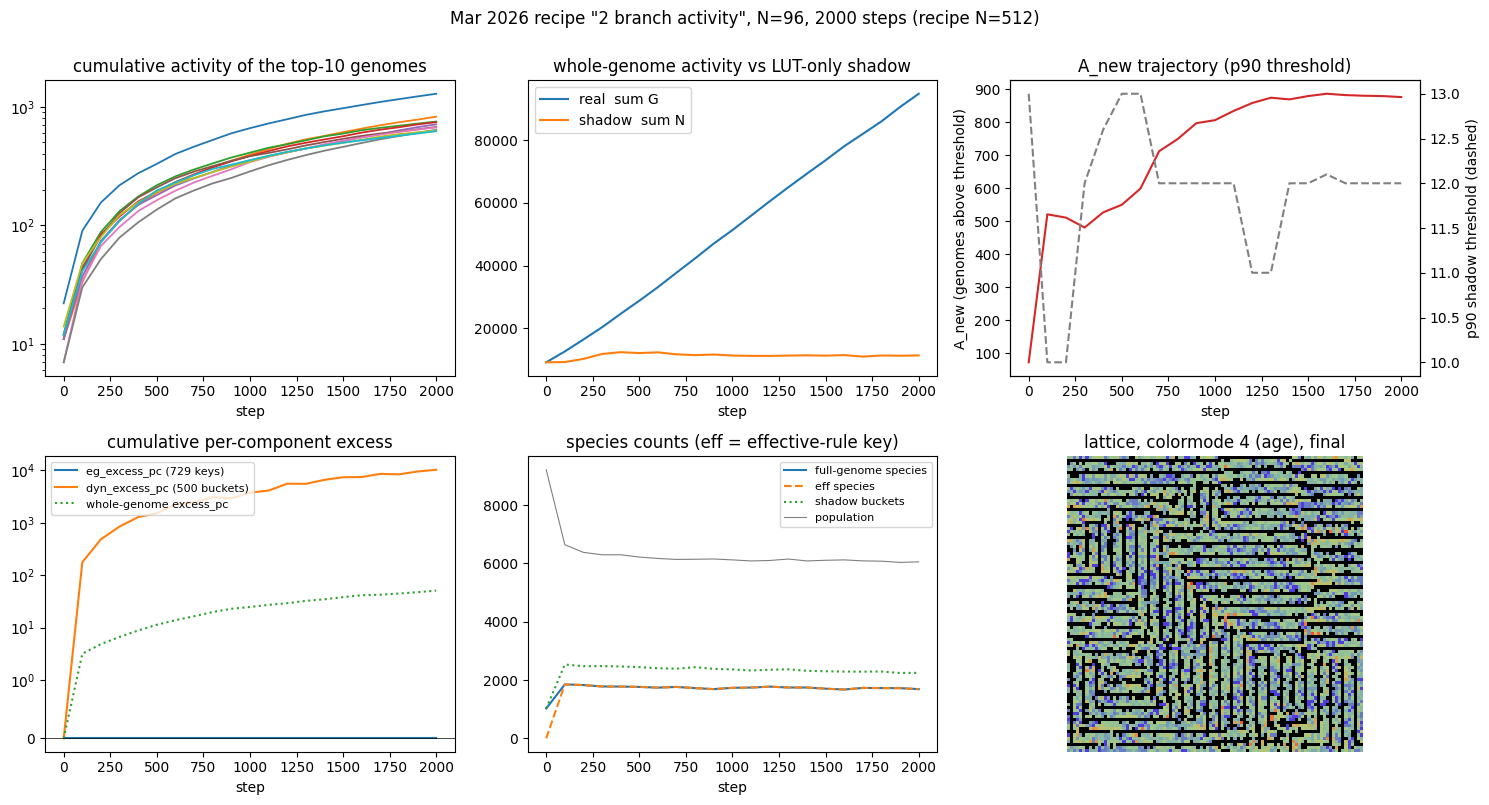

pop_final              6057.00
min_pop                6037.00
excess_slope             43.26
excess_pc_slope           0.03
eg_excess_slope           0.00
dyn_excess_slope          5.26
a_new_final             876.00
a_new_slope               0.29
full_species           1688.00
eff_species            1688.00
eg_keys_present           1.00
dyn_buckets_present     345.00
n_z3_dyn                105.00
n_z3_eg                   0.00
union-mask bits exercised: 250 / 250


In [4]:
sim, kw = load_recipe('2026-03-16_2_branch_activity.evoca', N=96, seed=0)
sim.set_lut_random(n_init=1, seed=0)   # the recipe's random LUT is unseeded; pin it so this run is reproducible
tr1 = trace(sim, n_steps=2000, every=100)
panel(tr1, 'Mar 2026 recipe "2 branch activity", N=96, 2000 steps (recipe N=512)')
print(pd.Series(summary_row(tr1)).round(2).to_string())
print('union-mask bits exercised:', tr1['union_bits'], '/ 250')

In [5]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# (the recipe was saved at N=512)
# from controls import run_with_controls
# sim, kw = load_recipe('2026-03-16_2_branch_activity.evoca', N=256, seed=0)
# sim.set_lut_random(n_init=1, seed=0)
# run_with_controls(sim, cell_px=2, **kw)

**Observed in this example run (N=96, not a campaign result).** The recipe has `m_scale = 0.4`, so the eating rule cannot bind here.

- Activity is "wave-like" in the top-left panel only in the trivial sense: the population keeps minting new genomes (1,688 alive species at the end, with 6,057 alive cells), and each new genome's cumulative activity rises from 1.
- This run has **no egene evolution** (`mu_egene=0`, one `eg` key present), so the LUT-only shadow matches the whole-genome hash in scope and the legacy excess is *valid* here, positive (slope +43 per tick) and visibly above the shadow in the top-middle panel. It is the one regime where the original 2026 audit target was well defined.
- `dyn` excess is positive (slope +5.3) and 105 of the 500 transition buckets are above z = 3. `A_new` ends at 876 (p90 threshold).
- **Effective-rule species equal full-genome species (1,688 = 1,688), and the population-union used-mask has all 250 bits set.** Silent LUT churn is not being removed by the merged `eff_activity` here; see the open question about the union mask in `ISSUES.md` (ACT-Q2).

**Direction that came out of it:** the strip chart cannot say whether a rising wave is adaptive or neutral churn; that is the audit program in the next sections.

## 2. 2026-04-27: `evo_focus`, optimizing the whole-genome excess composite

**Question.** After the balanced (spatial + evolution) scans, optimize purely for `EVO_METRICS` (`n_distinct_genomes_mean`, `n_distinct_genomes_temporal_std`, `unique_top_genomes`, legacy `excess_activity_slope`) near the productive corner: how far can genomic turnover and excess activity be pushed? Scan: [`Scans/2026-04-27_evo_focus/`](Scans/2026-04-27_evo_focus/notes.md) (250 configs, N=256, 5000 steps, 12 cores, 180 s).

**Recorded findings** (`notes.md`): the pure-evo composite max rose 0.637 to 0.724 (1.14x); the gain was in `n_distinct_genomes_temporal_std` (1.22x), while `excess_activity_slope` *fell* to 0.46x of the earlier max; **`mu_lut = 0.060` (the grid ceiling) won 3 of the top 5**, and `m_scale = 1.5` won four of five, so both levers were unbracketed. The note explained the falling excess slope as a high-mutation quirk of the Channon metric (the shadow grows proportionally faster). The note also records that the 50 baseline re-runs did not reproduce their `push_edges` originals because the C RNG was not reseeded between pool tasks (later fixed by `set_seed`, S1).

**What the later campaigns said about this** (section 4): the whole-genome excess is ill-defined for egene-driven runs and turnover-fragile at high `mu_lut`, so "`mu_lut` wants 0.06" is attributable to the metric, not to biology.

**Which model.** The table below reads the 2026-10-23 rescan ([`Scans/2026-10-23_evo_focus_standard`](Scans/2026-10-23_evo_focus_standard/notes.md)): the same 250 configs, N=256, 5000 steps, seed 0, today's code and the standard rule. This scan differs from today's model by more than the rule: it predates max-match eating and the egene-aware genome hash (2026-04-28) and ternary egenes with ±1 scoring (2026-05-10). Its driver passed `mu_egenome` meaning the egene mutation rate; since the 2026-04-28 rename that rate is `mu_egene` (and `mu_egenome` is the Negene slot-growth rate), so the rescan and the example runs below pass `mu_egene`. The recorded table is set against the rescan in the legacy section.

**Example runs.** (a) The recorded 04-27 winner (cfg 232) re-run at N=96 for 3000 steps with all probes; (b) a three-point `mu_lut` sweep on that base through `run_sim`, reporting the legacy and the new readouts side by side; (c) the recipe `2026-04-27_high_excess_activity_slope.evoca` (a copy of `push_edges` cfg 98, so named for the metric it was picked on, not for its excess), compared with its recorded row.

evo_focus rescan: 250 configs, 0 extinct, 250 candidates
top-5 by the EVO_METRICS composite (rescan, N=256, 5000 steps):


,config_idx,evo_score,param_food_inc,param_tax,param_gdiff,param_mu_lut,param_mu_egene,param_m_scale,param_restricted_mu,alive_density_mean,excess_activity_slope,dyn_excess_pc_slope,eg_excess_pc_slope
153,155,0.722,0.010,0.030,0.06,0.003,0.003,1.2,False,0.318,28.218,23.125,115.617
163,154,0.705,0.018,0.040,0.06,0.010,0.003,1.2,False,0.440,8.076,12.988,215.716
165,165,0.691,0.018,0.035,0.06,0.003,0.010,0.8,False,0.507,29.870,37.462,145.481
208,197,0.691,0.018,0.035,0.06,0.010,0.030,1.0,True,0.509,35.625,26.922,73.910
239,224,0.689,0.018,0.030,0.05,0.005,0.010,1.0,False,0.596,40.997,20.131,156.985


top-25 mu_lut counts: {0.003: 7, 0.005: 8, 0.01: 8, 0.02: 1, 0.06: 1}   m_scale counts: {0.8: 2, 1.0: 8, 1.2: 13, 1.5: 2}
recorded winner cfg 232 in the rescan: rank 50 of 250
alive_density_mean                     0.51
n_distinct_genomes_mean            33188.26
n_distinct_genomes_temporal_std     3960.74
unique_top_genomes                       40
excess_activity_slope                  32.3
dyn_excess_pc_slope                   18.39
eg_excess_pc_slope                    59.34


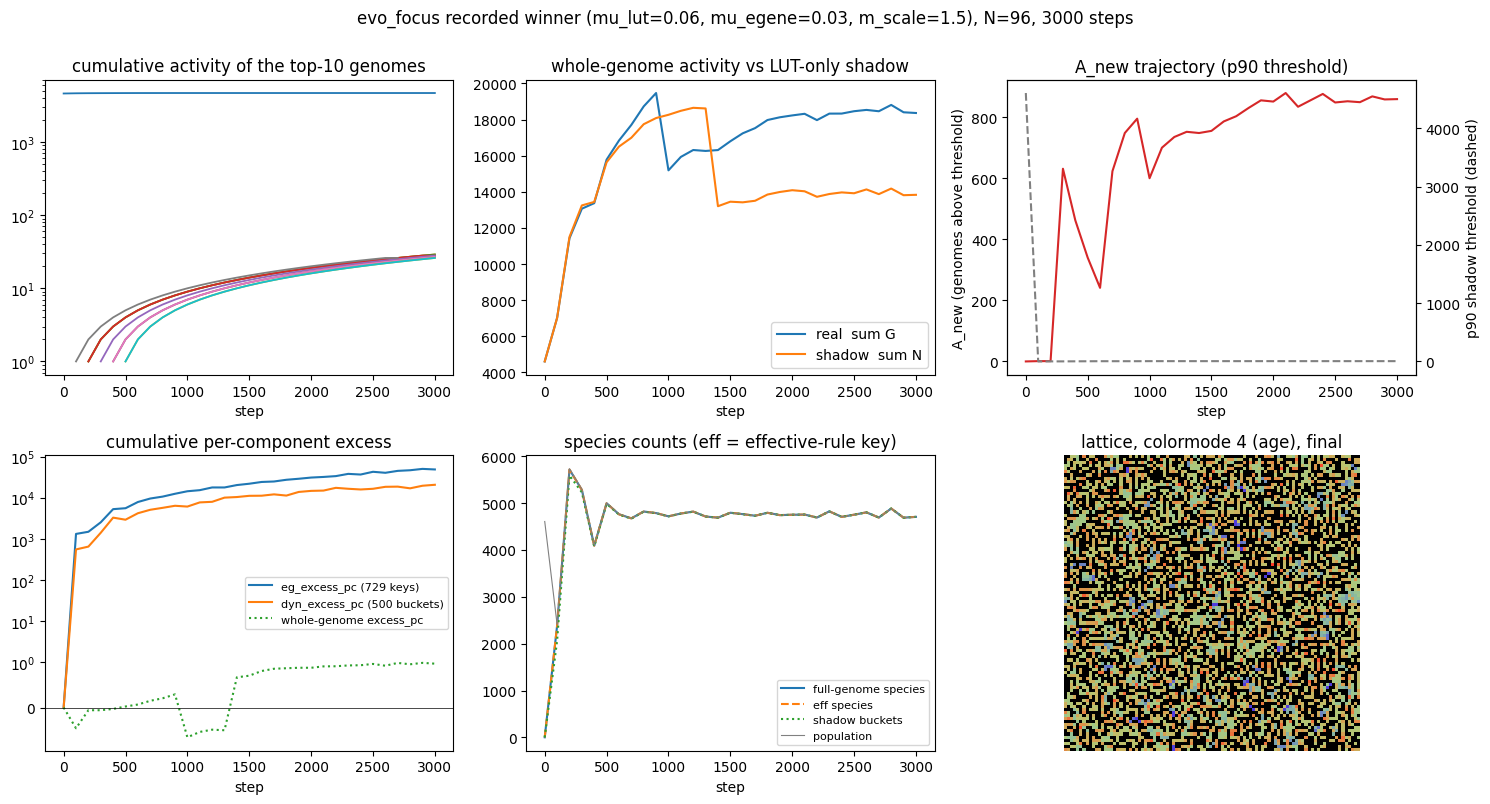

pop_final              4707.00
min_pop                2409.00
excess_slope              2.20
excess_pc_slope           0.00
eg_excess_slope          16.98
dyn_excess_slope          6.87
a_new_final             859.00
a_new_slope               0.24
full_species           4707.00
eff_species            4707.00
eg_keys_present         203.00
dyn_buckets_present     286.00
n_z3_dyn                117.00
n_z3_eg                 102.00
wall: 1.5s


In [6]:
EF_STD = SCANS/'2026-10-23_evo_focus_standard'   # standard-model rescan of 2026-04-27_evo_focus

def evo_composite(df):
    """The 04-27 ranking: candidates (not extinct, alive <= 0.95) scored by the
    mean of min-max normalized EVO_METRICS (evoca_from_scan_top's formula)."""
    c = df[(~df.extinct.astype(bool)) & (df.alive_density_mean <= 0.95)].copy()
    nrm = lambda a: (a - a.min()) / (a.max() - a.min()) if a.max() > a.min() else a * 0
    c['evo_score'] = sum(nrm(c[k]) for k in EVO_METRICS) / len(EVO_METRICS)
    return c.sort_values('evo_score', ascending=False)

rec = pd.read_csv(EF_STD/'results.csv')
ef = evo_composite(rec)
print(f'evo_focus rescan: {len(rec)} configs, {int(rec.extinct.sum())} extinct, {len(ef)} candidates')
EF_COLS = ['config_idx', 'evo_score', 'param_food_inc', 'param_tax', 'param_gdiff', 'param_mu_lut', 'param_mu_egene',
           'param_m_scale', 'param_restricted_mu', 'alive_density_mean', 'excess_activity_slope', 'dyn_excess_pc_slope', 'eg_excess_pc_slope']
print('top-5 by the EVO_METRICS composite (rescan, N=256, 5000 steps):'); display(ef.head(5)[EF_COLS].round(3))
print('top-25 mu_lut counts:', ef.head(25).param_mu_lut.value_counts().sort_index().to_dict(),
      '  m_scale counts:', ef.head(25).param_m_scale.value_counts().sort_index().to_dict())

# the recorded 04-27 winner (cfg 232); the April driver's mu_egenome is today's mu_egene
WIN = dict(food_inc=0.018, tax=0.035, gdiff=0.06, m_scale=1.5, mu_lut=0.06, mu_egene=0.03, restricted_mu=True)
W = ef[ef.config_idx == 232].iloc[0]
print(f'recorded winner cfg 232 in the rescan: rank {ef.index.get_loc(W.name) + 1} of {len(ef)}')
print(W[['alive_density_mean','n_distinct_genomes_mean','n_distinct_genomes_temporal_std','unique_top_genomes','excess_activity_slope',
         'dyn_excess_pc_slope','eg_excess_pc_slope']].round(2).to_string())

t0 = time.time()
sim = build_sim(WIN, N=96, seed=0)
tr2 = trace(sim, n_steps=3000, every=100)
panel(tr2, 'evo_focus recorded winner (mu_lut=0.06, mu_egene=0.03, m_scale=1.5), N=96, 3000 steps')
print(pd.Series(summary_row(tr2)).round(2).to_string())
print('wall: %.1fs' % (time.time()-t0))


In [7]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = build_sim(WIN, N=256, seed=0)
# run_with_controls(sim, cell_px=2, probes={'activity': True, 'n_activity': True, 'eg_activity': True, 'dyn_activity': True, 'ts': True})

**Sweep (b).** Same environment as the recorded evo_focus winner, `mu_lut` in {0.01, 0.03, 0.06}, one seed, N=96, 3000 steps. The table shows what each candidate readout would have said about "mu_lut wants 0.06".

In [8]:
# mu_lut sweep on the evo_focus base: do the rankings agree?  (run_sim = the public path used by scans)
rows = []
for mu in (0.01, 0.03, 0.06):
    o = run_sim(dict(WIN, mu_lut=mu), n_steps=3000, sample_every=100, N=96, seed=0, shadow=True)
    rows.append(dict(mu_lut=mu, alive_density=o['alive_density_mean'], excess_activity_slope=o['excess_activity_slope'],
                     excess_pc_slope=o['excess_pc_slope'], dyn_excess_pc_slope=o['dyn_excess_pc_slope'],
                     eg_excess_pc_slope=o['eg_excess_pc_slope'], a_new_final=o['a_new_final'],
                     a_new_slope=o['a_new_slope'], ndiv_sd=o['n_distinct_genomes_temporal_std']))
sw2 = pd.DataFrame(rows).set_index('mu_lut'); display(sw2.round(3))

,alive_density,excess_activity_slope,excess_pc_slope,dyn_excess_pc_slope,eg_excess_pc_slope,a_new_final,a_new_slope,ndiv_sd
mu_lut,,,,,,,,
0.01,0.510,1.544,0.0,9.176,13.777,595.0,0.165,954.839
0.03,0.510,1.723,0.0,7.789,15.971,855.0,0.213,963.661
0.06,0.511,2.201,0.0,6.870,16.983,859.0,0.238,964.105


In [9]:
# The same base as previously run here: mu_egenome=0.03 passed under today's meaning (Negene slot growth),
# mu_egene=0, so the egene does not mutate and one eg key is present (ACT-Q3: the eg_excess_pc guard case).
trQ3 = trace(build_sim(dict(WIN, mu_egene=0.0, mu_egenome=0.03), N=96, seed=0), n_steps=3000, every=100)
print('eg keys present: %d   eg_excess_pc slope: %.0f per tick   dyn_excess_pc slope: %.2f'
      % (trQ3['eg_D'][-1], slope(trQ3['t'], trQ3['eg']), slope(trQ3['t'], trQ3['dyn'])))


eg keys present: 1   eg_excess_pc slope: 14934 per tick   dyn_excess_pc slope: 5.93


In [10]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = build_sim(dict(WIN, mu_lut=0.01), N=256, seed=0)   # or mu_lut=0.03 / 0.06
# run_with_controls(sim, cell_px=2, probes={'activity': True, 'n_activity': True, 'eg_activity': True, 'dyn_activity': True, 'ts': True})

In [11]:
# The recipe filed as 2026-04-27_high_excess_activity_slope.evoca is a copy of push_edges cfg 98
# (descriptor "top_9_cfg98_score0.78"); compare with that row in Reaction-diffusion's standard-model rescan.
rd = pd.read_csv(ROOT/'Research'/'Reaction-diffusion'/'Scans'/'2026-10-23_rescan_0427_standard'/'results.csv')   # RD's standard-model rescan
r98 = rd[(rd.scan == 'push_edges') & (rd.config_idx == 98)].iloc[0]
print('push_edges cfg 98, rescan (N=256, 5000 steps): alive_density_mean=%.3f  excess_activity_slope=%.2f  n_distinct_mean=%.0f'
      % (r98.alive_density_mean, r98.excess_activity_slope, r98.n_distinct_genomes_mean))
sim, kw = load_recipe('2026-04-27_high_excess_activity_slope.evoca', N=96, seed=0)
tr2b = trace(sim, n_steps=3000, every=100)
print('population every 500 steps:', [int(p) for p in tr2b['pop'][::5]])
print('here (N=96, 3000 steps): alive_density_mean=%.3f  excess_slope=%.2f' % (tr2b['pop'].mean()/96**2, slope(tr2b['t'], tr2b['excess'])))
print(pd.Series(summary_row(tr2b)).round(2).to_string())

push_edges cfg 98, rescan (N=256, 5000 steps): alive_density_mean=0.357  excess_activity_slope=10.00  n_distinct_mean=16956
[food_cap] 2026-04-27_high_excess_activity_slope.evoca: no food_cap key and m_scale=1.2 > 1; running the standard capped rule. The legacy uncapped rule (pre-A9 fix) is food_cap=0.


population every 500 steps: [4608, 1844, 5415, 3393, 3075, 3598, 3312]
here (N=96, 3000 steps): alive_density_mean=0.352  excess_slope=0.89
pop_final              3312.00
min_pop                 553.00
excess_slope              0.89
excess_pc_slope           0.00
eg_excess_slope          14.85
dyn_excess_slope          8.45
a_new_final             184.00
a_new_slope               0.05
full_species           2496.00
eff_species            2496.00
eg_keys_present         155.00
dyn_buckets_present     214.00
n_z3_dyn                 70.00
n_z3_eg                 102.00


In [12]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim, kw = load_recipe('2026-04-27_high_excess_activity_slope.evoca', N=256, seed=0)
# run_with_controls(sim, cell_px=2, **kw)

**Observations.**

*The rescan.* Under today's model the 04-27 optimum does not survive, even under the metric it was picked on. The rescan has 0 extinct configs (recorded: 16). Its EVO_METRICS top-5 sits at `mu_lut` 0.003 to 0.01 and `m_scale` 0.8 to 1.2, and the top-25 hold one config at `mu_lut = 0.06` (recorded: 12 of 25). The recorded winner, cfg 232, ranks 50th of 250. The composite maximum is about the same (0.722; recorded 0.724).

*Example runs versus the rescan rows.* At N=96 / 3000 steps the recorded winner has alive density 0.51 (rescan 0.51), no extinction, and `excess_activity_slope` +2.2 (rescan +32.3 at N=256 / 5000 steps). For cfg 98 (c): alive density 0.35 (rescan 0.36), with a boom-and-bust population (1,844 to 5,415 cells across the 500-step samples, minimum 553; not extinct); its legacy excess slope is +0.9 here and +10.0 in the rescan. Densities agree. Absolute diversity and excess do not, because they scale with N and run length (`n_distinct` temporal std is about 960 here versus 3,961 in the rescan row).

*Observed in the example runs (N=96, not a campaign result).*

- In the `mu_lut` sweep the legacy excess slope **rises** with `mu_lut` (1.54, 1.72, 2.20), as do `eg_excess_pc_slope` (13.8, 16.0, 17.0) and `A_new` (595, 855, 859), while `dyn_excess_pc_slope` **falls** (9.18, 7.79, 6.87). The readouts disagree on direction: a ranking by legacy excess, `eg` or `A_new` says "go higher in `mu_lut`", one by `dyn` says "go lower". One seed at small N.
- **`eg_excess_pc` artifact (ACT-Q3).** This notebook previously ran the base with `mu_egenome = 0.03` under today's meaning of that name (Negene slot growth) and `mu_egene` unset, so the egene did not mutate. The cell after the sweep repeats that configuration: one `eg` key is present, and `eg_excess_pc_slope` reads 14,934 per tick, against 17 with the egene mutating (203 keys present) and 8 to 41 in the egene-evolving runs of sections 3 and 4. With a single real component the per-component normalization `sum G / D_G - sum N / D_N` is dominated by the shadow spreading over many keys while the real run sits on one. The number is an artifact of degenerate diversity, not selection. Any ranking that includes `eg_excess_pc` needs a guard on the number of keys present.
- The panel for the recorded winner shows the eff/full species counts coinciding again (4,707 = 4,707).

## 3. 2026-05-16 and 2026-05-17: reciprocal causal controls (v1, v2)

**Question.** Does the excess metric pass the sharp causal test: a subsystem that is frozen must show *zero* excess, and an evolving subsystem must show positive excess over its neutral shadow? And do the LUT (rule) and egene (cognition) subsystems co-evolve or evolve independently? Three arms at one productive corner: JOINT (both evolve), LUT_only (egene frozen), EGENE_only (LUT frozen on GoL). Scans [`2026-05-16_causal_control`](Scans/2026-05-16_causal_control/) (v1, N=128, 3000 steps, 3 seeds) and [`2026-05-17_causal_control_v2`](Scans/2026-05-17_causal_control_v2/notes.md) (v2, N=256, 15000 steps, 4 seeds; each (arm, seed) in its own process).

**Recorded findings.** v1 exposed a **scope bug**: the Channon shadow carries LUT bytes only while `get_activity` hashes the full genome, so for the EGENE_only arm the whole-genome excess read about -26 (an artifact). v2 added the fixed-space shadows (eg 729 keys, dyn 500 buckets) and they **pass the nulls exactly**: LUT_only gives `eg_excess = 0.000`, EGENE_only gives `dyn_excess = 0.000`, while whole-genome `excess_pc` remains pathological (-46) for the EGENE_only arm. JOINT exceeds both isolated arms in both channels (eg 65 vs 31; dyn 33 vs 17), read as mutual amplification, with a flagged **frozen-substrate confound** (the frozen subsystem sits at GoL or uniform, not an optimum).

**Which model.** The tables below read the 2026-10-23 standard-model rescans ([`2026-10-23_causal_control_standard`](Scans/2026-10-23_causal_control_standard/notes.md), [`2026-10-23_causal_control_v2_standard`](Scans/2026-10-23_causal_control_v2_standard/notes.md)): the same drivers, arms, seeds, N and steps at `m_scale = 1.2`, where the rule can bind. The recorded v2 table is set against the rescan in the legacy section.

**Example runs.** The three arms re-run through `run_sim` at N=96, 3000 steps, 2 seeds each (6 runs), with the new `A_new` readout alongside.

In [13]:
v1 = pd.read_csv(SCANS/'2026-10-23_causal_control_standard'/'results.csv')     # standard-model rescans
v2 = pd.read_csv(SCANS/'2026-10-23_causal_control_v2_standard'/'results.csv')
print('v1 rescan (N=128, 3000 steps; 3 seeds), mean by arm:')
display(v1.groupby('arm', sort=False)[['excess_pc_slope','excess_activity_slope','n_distinct_genomes_mean']].mean().round(4))
print('v2 rescan (N=256, 15000 steps; 4 seeds), mean by arm:')
display(v2.groupby('arm', sort=False)[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_mean']].mean().round(3))

BASE = dict(food_inc=0.013, m_scale=1.2, gdiff=0.06, tax=0.035, tax_per_egene=8e-4)
ARMS = {'JOINT': dict(BASE, mu_lut=0.01, mu_egene=0.003, mu_egenome=0.005),
        'LUT_only': dict(BASE, mu_lut=0.01, mu_egene=0.0, mu_egenome=0.0),
        'EGENE_only': dict(BASE, mu_lut=0.0, mu_egene=0.003, mu_egenome=0.005)}
rows = []
for arm, p in ARMS.items():
    for seed in (0, 1):
        o = run_sim(p, n_steps=3000, sample_every=100, N=96, seed=seed, shadow=True)
        rows.append(dict(arm=arm, seed=seed, final_pop=o['final_pop'], excess_pc_slope=o['excess_pc_slope'],
                         eg_excess_pc_slope=o['eg_excess_pc_slope'], dyn_excess_pc_slope=o['dyn_excess_pc_slope'],
                         a_new_final=o['a_new_final'], excess_activity_slope=o['excess_activity_slope']))
cc = pd.DataFrame(rows)
print('REPRODUCED here (N=96, 3000 steps, 2 seeds):')
display(cc.round(4))
display(cc.groupby('arm', sort=False)[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','a_new_final']].mean().round(3))

v1 rescan (N=128, 3000 steps; 3 seeds), mean by arm:


,excess_pc_slope,excess_activity_slope,n_distinct_genomes_mean
arm,,,
JOINT,0.0046,1.8721,2883.3011
LUT_only,0.0023,1.3939,2074.4409
EGENE_only,-32.6104,-11.3202,192.3978


v2 rescan (N=256, 15000 steps; 4 seeds), mean by arm:


,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,n_distinct_genomes_mean
arm,,,,
JOINT,0.000,63.248,31.084,15947.148
LUT_only,0.000,0.000,17.154,9343.221
EGENE_only,-68.036,45.034,0.000,654.221


REPRODUCED here (N=96, 3000 steps, 2 seeds):


,arm,seed,final_pop,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,a_new_final,excess_activity_slope
0,JOINT,0,2549,0.0047,14.0019,6.0395,374.0,0.7963
1,JOINT,1,2416,0.0028,9.7517,4.8843,360.0,0.5543
2,LUT_only,0,1371,0.0018,0.0000,5.2212,147.0,0.5623
3,LUT_only,1,1434,0.0019,0.0000,4.9880,150.0,0.5696
4,EGENE_only,0,2653,-16.8710,8.1821,0.0000,0.0,-7.7685
5,EGENE_only,1,2620,-16.5002,7.9332,0.0001,0.0,-7.0497


,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,a_new_final
arm,,,,
JOINT,0.004,11.877,5.462,367.0
LUT_only,0.002,0.000,5.105,148.5
EGENE_only,-16.686,8.058,0.000,0.0


In [14]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = build_sim(ARMS['JOINT'], N=256, seed=0)   # or ARMS['LUT_only'] / ARMS['EGENE_only']
# run_with_controls(sim, cell_px=2, probes={'activity': True, 'n_activity': True, 'eg_activity': True, 'dyn_activity': True, 'ts': True})

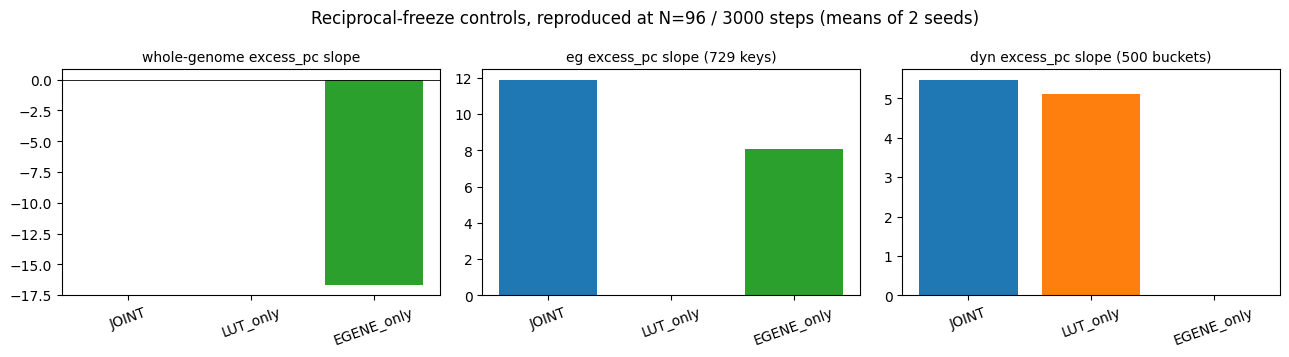

LUT_only  eg_excess_pc_slope  per seed: ['0.00e+00', '0.00e+00']
EGENE_only dyn_excess_pc_slope per seed: ['0.00e+00', '6.05e-05']
null invariants hold to < 1e-3 per tick (the live arms sit at ~5-15)


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
g = cc.groupby('arm', sort=False)
for a, col, ttl in zip(ax, ['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope'],
                       ['whole-genome excess_pc slope','eg excess_pc slope (729 keys)','dyn excess_pc slope (500 buckets)']):
    m = g[col].mean(); a.bar(m.index, m.values, color=['C0','C1','C2']); a.axhline(0, c='k', lw=.6); a.set_title(ttl, fontsize=10)
    a.tick_params(axis='x', labelrotation=20)
fig.suptitle('Reciprocal-freeze controls, reproduced at N=96 / 3000 steps (means of 2 seeds)'); fig.tight_layout(); plt.show()
print('LUT_only  eg_excess_pc_slope  per seed:', [f'{x:.2e}' for x in cc[cc.arm=='LUT_only'].eg_excess_pc_slope])
print('EGENE_only dyn_excess_pc_slope per seed:', [f'{x:.2e}' for x in cc[cc.arm=='EGENE_only'].dyn_excess_pc_slope])
assert (cc[cc.arm=='LUT_only'].eg_excess_pc_slope.abs() < 1e-3).all(), 'eg null violated'
assert (cc[cc.arm=='EGENE_only'].dyn_excess_pc_slope.abs() < 1e-3).all(), 'dyn null violated'
print('null invariants hold to < 1e-3 per tick (the live arms sit at ~5-15)')

**The rescans.** The fixed-space nulls hold exactly: v2 LUT_only `eg_excess = 0.000`, EGENE_only `dyn_excess = 0.000`. Whole-genome `excess_pc` stays pathological for EGENE_only (-32.6 in v1, -68.0 in v2; recorded -25.9 and -46.4). JOINT still exceeds both isolated arms, by less in `eg`: JOINT 63.2 versus EGENE_only 45.0 (1.4x; recorded 64.8 versus 31.0, 2.1x); `dyn` JOINT 31.1 versus LUT_only 17.2 (1.8x; recorded 33.0 versus 17.3). The `eg` part of "mutual amplification" shrinks under the standard rule because the EGENE_only arm gains; JOINT and LUT_only barely move.

**Observed in these example runs (N=96, 2 seeds, not a campaign result).**

- **Nulls reproduce.** LUT_only: `eg_excess_pc_slope` is exactly 0 in both seeds. EGENE_only: `dyn_excess_pc_slope` is 0 and 6e-5 (not bit-exact zero in one seed; negligible against live values of 5 to 14, so the assertion uses a 1e-3 tolerance rather than equality).
- **The whole-genome pathology reproduces:** EGENE_only whole-genome `excess_pc_slope` is -16.7 (seeds -16.9, -16.5); JOINT and LUT_only are about +0.002 to +0.005.
- **The `dyn` ordering reproduces weakly** (JOINT 5.5 > LUT_only 5.1 > EGENE_only 0). **The `eg` ordering matches the rescans at this scale too:** JOINT 11.9 (seeds 14.0, 9.8) above EGENE_only 8.1 (8.2, 7.9). The two seeds of each arm are closer than the seed spread recorded in ISSUES (ACT-Q8), but two seeds cannot settle it.
- **`A_new` inherits the LUT-only shadow mismatch.** In the EGENE_only arm (LUT frozen, egene evolving, `eg_excess` clearly positive) `A_new = 0` in both seeds, because the real side is keyed by the whole genome (many egene variants) while the shadow side is a single LUT bucket with a very large activity, so no real genome clears the p90 threshold. `A_new`, as merged, is valid only where the egene is not evolving, the same scope limit as the legacy excess (ACT-Q1).

## 4. 2026-05-17: the pure-evolution campaign (#1 joint, #2 LUT-only) and the metric choice

**Question.** If we optimize purely for evolutionary metrics with the corrected (fixed-space) excess, which regime is selected, and does it differ from the 2026-04-27 balanced and evo-focused optima? Scans [`pure_evo_joint`](Scans/2026-05-17_pure_evo_joint/notes.md) (300 configs, 284 candidates, LUT + egene evolving, N=256, 8000 steps) and [`pure_evo_lut_only`](Scans/2026-05-17_pure_evo_lut_only/notes.md) (180 configs, egene frozen incl. `tax_per_egene = 0`); analysis [`2026-05-17_pure_evo_analysis.md`](Scans/2026-05-17_pure_evo_analysis.md); digest draft [`digests/pure-evo-regime.ipynb`](digests/pure-evo-regime.ipynb).

**Recorded findings.** Whole-genome `excess_pc_slope` is about 0 everywhere; `dyn` (about 23 to 60) and `eg` (about 40 to 135) excess are strongly positive. Under the composite (unweighted mean of five min-max normalized, positive-clipped keys) the optimum is **low `mu_lut` (0.01) with high `m_scale` (2.5)**, the opposite of the 04-27 optimum; the `mu_lut` optimum is **conditional on the egene regime** (low when egene co-evolves, high when frozen); `m_scale` still sits at the grid ceiling (R1).

### 4a. What the scan data say, re-read (computed here from the rescan CSVs)

These cells use only the 2026-10-23 standard-model rescans ([`2026-10-23_pure_evo_joint_standard`](Scans/2026-10-23_pure_evo_joint_standard/notes.md), [`2026-10-23_pure_evo_lut_only_standard`](Scans/2026-10-23_pure_evo_lut_only_standard/notes.md); same configs and protocol, the rule can bind in the 237 of 300 and 151 of 180 rows with `m_scale > 1`); nothing is re-simulated. The recorded headline numbers are set against them in the legacy section. The rank-correlation matrix and the last cell (objective comparison) are **new analyses made for this notebook**, not part of the 2026-05-17 write-up.

In [16]:
J = pd.read_csv(SCANS/'2026-10-23_pure_evo_joint_standard'/'results.csv')        # standard-model rescans
L = pd.read_csv(SCANS/'2026-10-23_pure_evo_lut_only_standard'/'results.csv')
Jc = J[(~J.extinct.astype(bool)) & (J.alive_density_mean <= 0.95)]
Lc = L[(~L.extinct.astype(bool)) & (L.alive_density_mean <= 0.95)]
print(f'joint: {len(J)} configs, {len(Jc)} candidates; lut_only: {len(L)} configs, {len(Lc)} candidates')
print('joint candidates, medians:'); print(Jc[['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope']].median().round(4).to_string())
cols = ['excess_activity_slope','excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_temporal_std','unique_top_genomes','n_distinct_genomes_mean']
print('\nSpearman rank correlation among the joint-scan candidates (rescan):')
display(Jc[cols].corr(method='spearman').round(2))

joint: 300 configs, 291 candidates; lut_only: 180 configs, 180 candidates
joint candidates, medians:
excess_pc_slope         0.0003
eg_excess_pc_slope     16.1040
dyn_excess_pc_slope    22.6073

Spearman rank correlation among the joint-scan candidates (rescan):


,excess_activity_slope,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope,n_distinct_genomes_temporal_std,unique_top_genomes,n_distinct_genomes_mean
excess_activity_slope,1.00,0.11,0.34,0.69,0.19,-0.58,0.50
excess_pc_slope,0.11,1.00,0.52,0.10,0.28,0.03,-0.66
eg_excess_pc_slope,0.34,0.52,1.00,0.38,0.33,-0.14,-0.11
dyn_excess_pc_slope,0.69,0.10,0.38,1.00,-0.11,-0.43,0.21
n_distinct_genomes_temporal_std,0.19,0.28,0.33,-0.11,1.00,0.02,0.09
unique_top_genomes,-0.58,0.03,-0.14,-0.43,0.02,1.00,-0.42
n_distinct_genomes_mean,0.50,-0.66,-0.11,0.21,0.09,-0.42,1.00


In [17]:
# Marginal means of dyn_excess_pc_slope by lever (rescan CSVs)
a = Jc.groupby('param_mu_lut').dyn_excess_pc_slope.mean().rename('joint (LUT+egene)')
b = Lc.groupby('param_mu_lut').dyn_excess_pc_slope.mean().rename('LUT-only (egene frozen)')
display(pd.concat([a, b], axis=1).round(2))
c = Jc.groupby('param_m_scale').dyn_excess_pc_slope.mean().rename('joint'); d = Lc.groupby('param_m_scale').dyn_excess_pc_slope.mean().rename('LUT-only')
display(pd.concat([c, d], axis=1).round(2))

,joint (LUT+egene),LUT-only (egene frozen)
param_mu_lut,,
0.01,23.57,29.56
0.03,27.79,23.00
0.06,29.91,28.11
0.10,27.02,25.09
0.15,24.12,24.54


,joint,LUT-only
param_m_scale,,
1.0,27.08,26.67
1.2,30.64,33.15
1.5,27.23,32.55
2.0,25.60,20.28
2.5,20.88,18.64


top-5 by composite


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
28,0.018,0.035,0.08,2.5,0.01,0.001,0.519,142.743,36.759
198,0.010,0.030,0.08,1.2,0.03,0.001,0.499,91.918,57.387
7,0.010,0.030,0.08,1.2,0.03,0.001,0.476,91.364,58.666
70,0.018,0.030,0.06,1.5,0.01,0.001,0.467,113.079,25.741
26,0.013,0.030,0.08,1.5,0.06,0.001,0.460,80.654,55.520


top-5 by dyn_excess_pc_slope


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
292,0.01,0.03,0.08,1.5,0.01,0.0,0.415,9.468,82.841
83,0.01,0.03,0.08,2.0,0.06,0.0,0.357,6.630,76.382
240,0.01,0.03,0.08,1.2,0.03,0.0,0.339,0.018,75.787
276,0.01,0.03,0.08,2.0,0.06,0.0,0.350,10.699,75.669
257,0.01,0.03,0.08,1.5,0.03,0.0,0.405,20.093,75.232


top-5 by eg_excess_pc_slope


,param_food_inc,param_tax,param_gdiff,param_m_scale,param_mu_lut,param_tax_per_egene,composite,eg_excess_pc_slope,dyn_excess_pc_slope
107,0.018,0.030,0.06,2.0,0.10,0.001,0.435,149.599,22.748
28,0.018,0.035,0.08,2.5,0.01,0.001,0.519,142.743,36.759
202,0.018,0.030,0.08,2.5,0.10,0.001,0.413,118.049,36.092
166,0.018,0.030,0.06,2.0,0.06,0.001,0.380,113.627,24.183
70,0.018,0.030,0.06,1.5,0.01,0.001,0.467,113.079,25.741


Spearman of composite with eg / dyn excess: {'composite': 1.0, 'eg_excess_pc_slope': 0.72, 'dyn_excess_pc_slope': 0.37}


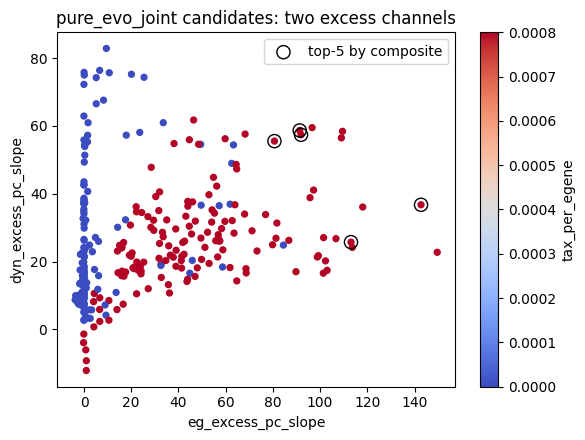

In [18]:
# NEW here (not in the 2026-05-17 analysis): does the *choice of objective* change the winner?  Same candidates (rescan).
keys5 = ['excess_pc_slope','eg_excess_pc_slope','dyn_excess_pc_slope','n_distinct_genomes_temporal_std','unique_top_genomes']
X = Jc[keys5].clip(lower=0); X = (X - X.min()) / (X.max() - X.min()); Jc = Jc.assign(composite=X.mean(axis=1))
pc = ['param_food_inc','param_tax','param_gdiff','param_m_scale','param_mu_lut','param_tax_per_egene']
show = pc + ['composite','eg_excess_pc_slope','dyn_excess_pc_slope']
for k in ('composite', 'dyn_excess_pc_slope', 'eg_excess_pc_slope'):
    print('top-5 by', k); display(Jc.sort_values(k, ascending=False).head(5)[show].round(3))
print('Spearman of composite with eg / dyn excess:', Jc[['composite','eg_excess_pc_slope','dyn_excess_pc_slope']].corr('spearman').round(2).composite.to_dict())
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(Jc.eg_excess_pc_slope, Jc.dyn_excess_pc_slope, c=Jc.param_tax_per_egene, cmap='coolwarm', s=18)
top = Jc.sort_values('composite', ascending=False).head(5)
ax.scatter(top.eg_excess_pc_slope, top.dyn_excess_pc_slope, s=90, facecolors='none', edgecolors='k', label='top-5 by composite')
ax.set_xlabel('eg_excess_pc_slope'); ax.set_ylabel('dyn_excess_pc_slope'); ax.legend(); plt.colorbar(sc, label='tax_per_egene')
ax.set_title('pure_evo_joint candidates: two excess channels'); fig.tight_layout(); plt.show()

**Observations from the rescan CSVs (new here, analysis of existing data).** 9 of 300 joint configs are extinct (recorded 16), leaving 291 candidates; the LUT-only scan has 0 extinct.

- **The legacy `EVO_METRICS` set is internally contradictory.** Among the joint candidates `unique_top_genomes` is anti-correlated with `dyn_excess_pc_slope` (Spearman -0.43) and with the legacy `excess_activity_slope` (-0.58), and `n_distinct_genomes_temporal_std` is uncorrelated with `dyn` (-0.11) and weakly correlated with `eg` (0.33). A mean of these keys rewards both turnover and its opposite.
- **The pure-evo composite is dominated by the `eg` channel** (Spearman with `eg_excess_pc_slope` 0.72, with `dyn_excess_pc_slope` 0.37). The composite winner is still cfg 41 (`m_scale` 2.5, `mu_lut` 0.01; `eg` 142.7, `dyn` 36.8). The top-5 by composite and the top-5 by `dyn` alone share *no* config, and the `eg` and `dyn` leaders sit in different corners: the `eg` leaders and the composite leaders all have `tax_per_egene = 0.0008` (the `eg` leaders also `food_inc = 0.018`); the `dyn` leaders all have `food_inc = 0.010`, `tax = 0.030`, `gdiff = 0.08`, **`tax_per_egene = 0`**, and `m_scale` 1.2 to 2.0. The scatter shows the two channels as a trade-off front, which is what a two-objective selection (ACT-D2) is for.
- **`m_scale = 2.5` is the best-looking value only through the `eg` channel.** The marginal mean of `dyn_excess_pc_slope` by `m_scale` is 27.1, 30.6, 27.2, 25.6, 20.9 for 1.0, 1.2, 1.5, 2.0, 2.5 (joint; LUT-only 26.7, 33.2, 32.6, 20.3, 18.6), so the composite winner at 2.5 is at the *worst* marginal `dyn` value.
- **The "conditional `mu_lut` optimum" is not visible in the marginal means.** Mean `dyn_excess_pc_slope` by `mu_lut` is non-monotone and flat-ish in both scans (joint: 23.6, 27.8, 29.9, 27.0, 24.1; LUT-only: 29.6, 23.0, 28.1, 25.1, 24.5 for 0.01 to 0.15). The recorded statement is about *top-ranked* configs under the composite, so it depends on the metric choice and on the interaction with `m_scale` and `tax_per_egene`, not on a clear marginal trend. Also, scan #2 freezes the egene by zeroing `tax_per_egene` as well as the mutation rates, so #1 versus #2 confounds egene *mutation* with egene *cost*; the v2 controls (which keep `tax_per_egene = 8e-4` in all arms) do not have this confound.

### 4b. Example runs: one pure-evo winner and its frozen control

The pure-evo winner is campaign #1 rank 1 (cfg 41: `food_inc` 0.018, `tax` 0.035, `gdiff` 0.08, `m_scale` 2.5, `mu_lut` 0.01, `mu_egene` 0.003, `mu_egenome` 0.003, `tax_per_egene` 8e-4). The control is **the same environment with all mutation frozen** (`mu_lut = mu_egene = mu_egenome = 0`) and `tax_per_egene = 0`. Both are saved as recipes ([`Runs/2026-10-15_pure_evo_joint_winner.evoca`](Runs/2026-10-15_pure_evo_joint_winner.evoca), [`Runs/2026-10-15_pure_evo_frozen_control.evoca`](Runs/2026-10-15_pure_evo_frozen_control.evoca), N=256 with the activity probes on) and loaded here through `import_run` at N=96. (Why `tax_per_egene = 0` in the control: under the legacy rule, the winner's `tax_per_egene = 8e-4` with every mutation rate zero went **extinct** in two of two N=96 runs, whereupon the fixed-space excess prints a meaningless large negative constant. Under the standard rule the same frozen config survives both seeds (legacy section), so a cost-matched frozen control is now possible. The extinction guard still matters for any scan that includes frozen arms.)

[food_cap] 2026-10-15_pure_evo_joint_winner.evoca: no food_cap key and m_scale=2.5 > 1; running the standard capped rule. The legacy uncapped rule (pre-A9 fix) is food_cap=0.


[food_cap] 2026-10-15_pure_evo_frozen_control.evoca: no food_cap key and m_scale=2.5 > 1; running the standard capped rule. The legacy uncapped rule (pre-A9 fix) is food_cap=0.


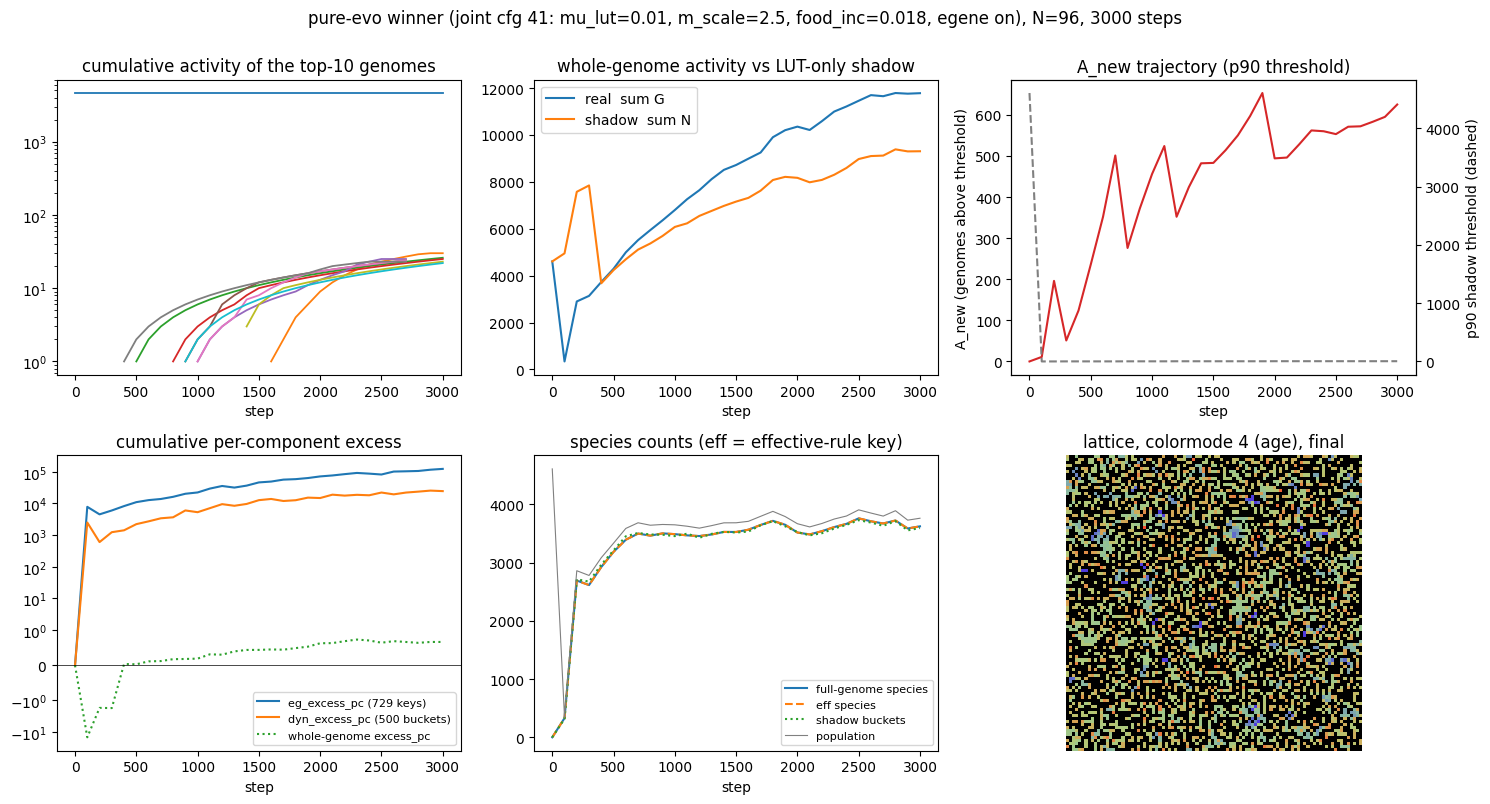

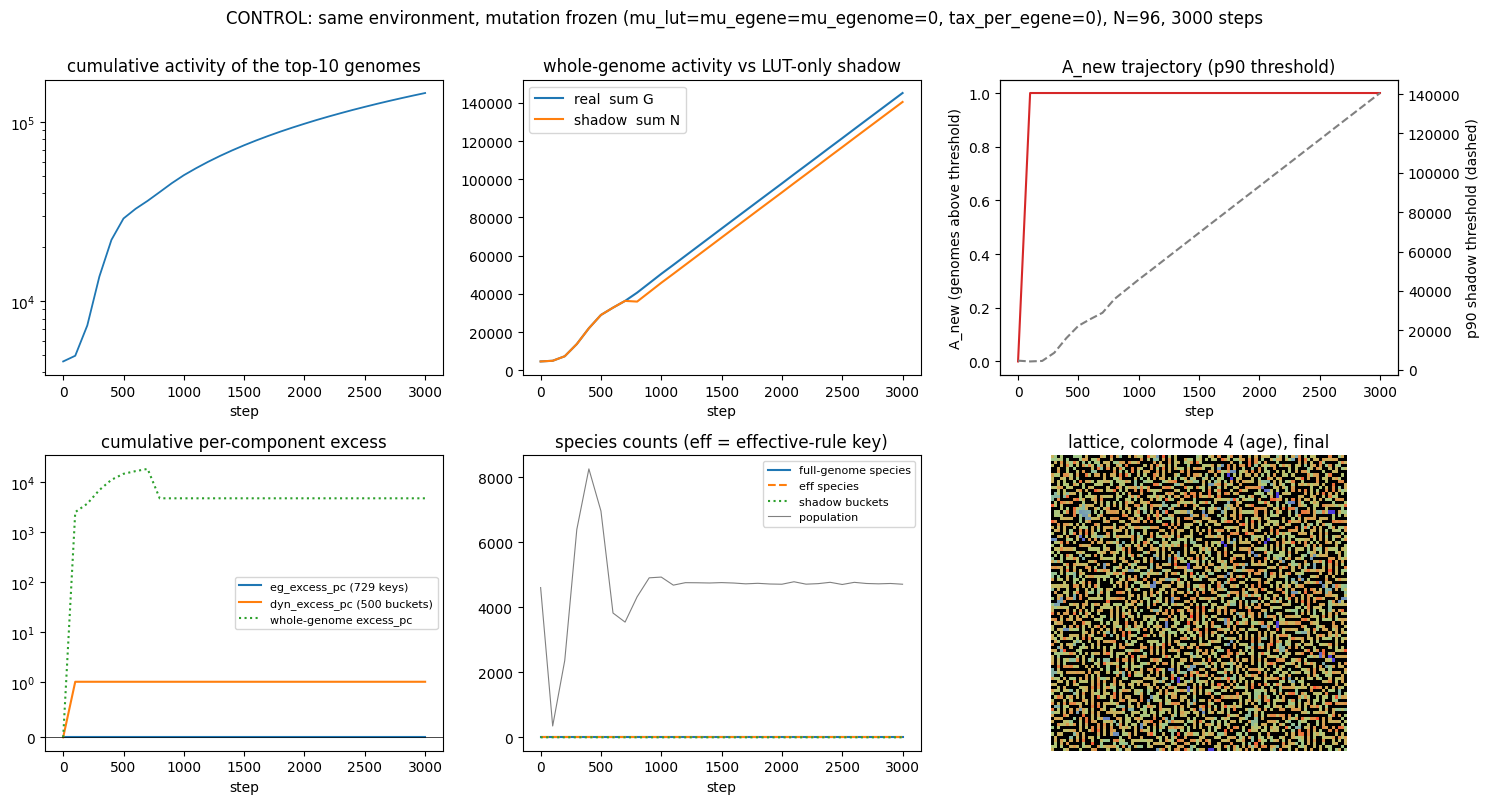

,winner,frozen control
pop_final,3761.000,4711.000
min_pop,343.000,349.000
excess_slope,1.788,1.738
excess_pc_slope,0.001,-1.177
eg_excess_slope,40.990,0.000
dyn_excess_slope,8.715,0.000
a_new_final,625.000,1.000
a_new_slope,0.175,0.000
full_species,3622.000,1.000
eff_species,3622.000,1.000


legacy whole-genome totals at the end of the CONTROL: sum G = 145198, sum N = 140514 (population ~4711)
union mask bits exercised: winner 250  control 250 / 250
wall 2.5s


In [19]:
t0 = time.time()
simW, kw = load_recipe('2026-10-15_pure_evo_joint_winner.evoca', N=96, seed=0)
trW = trace(simW, n_steps=3000, every=100)
simC, kw = load_recipe('2026-10-15_pure_evo_frozen_control.evoca', N=96, seed=0)
trC = trace(simC, n_steps=3000, every=100)
panel(trW, 'pure-evo winner (joint cfg 41: mu_lut=0.01, m_scale=2.5, food_inc=0.018, egene on), N=96, 3000 steps')
panel(trC, 'CONTROL: same environment, mutation frozen (mu_lut=mu_egene=mu_egenome=0, tax_per_egene=0), N=96, 3000 steps')
cmp_ = pd.DataFrame({'winner': summary_row(trW), 'frozen control': summary_row(trC)}); display(cmp_.round(3))
print('legacy whole-genome totals at the end of the CONTROL: sum G = %.0f, sum N = %.0f (population ~%d)' % (trC['G_tot'][-1], trC['N_tot'][-1], trC['pop'][-1]))
print('union mask bits exercised: winner', trW['union_bits'], ' control', trC['union_bits'], '/ 250')
print('wall %.1fs' % (time.time()-t0))

In [20]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# simW, kw = load_recipe('2026-10-15_pure_evo_joint_winner.evoca', N=256, seed=0)
# run_with_controls(simW, cell_px=2, **kw)
# # the frozen control instead:
# # simC, kw = load_recipe('2026-10-15_pure_evo_frozen_control.evoca', N=256, seed=0)
# # run_with_controls(simC, cell_px=2, **kw)

**Observed in these example runs (N=96, 3000 steps, not a campaign result).**

- **The null holds at every layer for the control.** One genome, one `eg` key and one `dyn` bucket present; `eg_excess = 0`, `dyn_excess = 0`, every per-bucket z-score is exactly 0, `n_z3 = 0` (see the z-score cell below).
- **The winner shows selection in both fixed spaces:** `eg` excess slope +41.0 and `dyn` excess slope +8.7 per tick (with 67 `eg` keys and 228 `dyn` buckets present), 100 of 500 `dyn` buckets and 58 of 729 `eg` keys above z = 3; `A_new` ends at 625.
- **The whole-genome readouts are not clean in either direction.** For the winner, whole-genome `excess_pc_slope` is 0.001 (flat, as recorded for #1). For the *control*, the real and shadow sums differ by 3% (145,198 versus 140,514) on a **single** component, so the cumulative per-component excess is their difference, 4,684: **the legacy readout is not a null under a freeze, the fixed-space readouts are.** `A_new` for the control is 1, not 0, for the same reason (the lone genome sits just above the shadow's lone bucket).
- **Waves.** In the winner the original (GoL) genome's activity stays flat on top after it dies out, and the new genomes reach only a few tens of ticks of cumulative activity in 3000 steps, so the strip chart shows a dense carpet of short-lived genomes, not discrete waves. The population minimum is 343 (winner) and 349 (control); the legacy-rule winner dipped much lower (legacy section).
- **Effective-rule species again equal full-genome species** (3,622 = 3,622) with all 250 union-mask bits set, in both the winner and (trivially) the control.

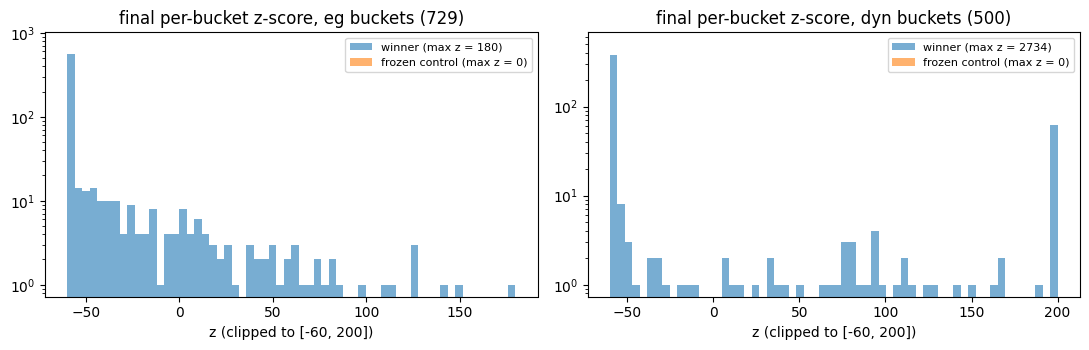

frozen control: max |z| eg = 0.00e+00, dyn = 0.00e+00
winner: eg buckets z>3: 58 / 729 ; dyn buckets z>3: 100 / 500


In [21]:
# per-bucket z-scores (G2): how concentrated is the signal?
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, key, ttl in zip(ax, ['egz', 'dyz'], ['eg buckets (729)', 'dyn buckets (500)']):
    for tr, lab in ((trW, 'winner'), (trC, 'frozen control')):
        z = tr[key]; z = z[z != 0] if lab == 'winner' else z
        a.hist(np.clip(z, -60, 200), bins=60, alpha=.6, label=f'{lab} (max z = {tr[key].max():.0f})')
    a.set_yscale('log'); a.set_xlabel('z (clipped to [-60, 200])'); a.set_title('final per-bucket z-score, ' + ttl); a.legend(fontsize=8)
fig.tight_layout(); plt.show()
print('frozen control: max |z| eg = %.2e, dyn = %.2e' % (np.abs(trC['egz']).max(), np.abs(trC['dyz']).max()))
print('winner: eg buckets z>3: %d / 729 ; dyn buckets z>3: %d / 500' % ((trW['egz']>3).sum(), (trW['dyz']>3).sum()))

In [22]:
# Public-boundary consistency check: trace() (this notebook) vs run_sim() (scan harness), identical config and seed.
P_W = dict(food_inc=0.018, tax=0.035, gdiff=0.08, m_scale=2.5, mu_lut=0.01, mu_egene=0.003, mu_egenome=0.003,
           tax_per_egene=8e-4, restricted_mu=False)
o = run_sim(P_W, n_steps=3000, sample_every=100, N=96, seed=0, shadow=True)
trX = trace(build_sim(P_W, N=96, seed=0), n_steps=3000, every=100)
print('run_sim a_new_final=%.0f  trace=%.0f | dyn_excess_pc_final run_sim=%.3f trace=%.3f | eg_excess_pc_final run_sim=%.3f trace=%.3f'
      % (o['a_new_final'], trX['a_new'][-1], o['dyn_excess_pc_final'], trX['dyn'][-1], o['eg_excess_pc_final'], trX['eg'][-1]))
assert o['a_new_final'] == trX['a_new'][-1] and abs(o['dyn_excess_pc_final'] - trX['dyn'][-1]) < 1e-6
print('(the recipe-path winner above gives a_new_final = %.0f; it differs only through the initial v-field / RNG stream)' % trW['a_new'][-1])

run_sim a_new_final=703  trace=703 | dyn_excess_pc_final run_sim=27042.830 trace=27042.830 | eg_excess_pc_final run_sim=108550.712 trace=108550.712
(the recipe-path winner above gives a_new_final = 625; it differs only through the initial v-field / RNG stream)


### 4c. D1 verdict readout (`dyn_report`) on the same two configs

`dyn_report` (D1, [`python/dyn_analysis.py`](../../python/dyn_analysis.py)) crosses a churn track (full-genome new-species rate) with a function track (`dyn_eff`, the participation ratio of the 500 transition buckets) and returns a verdict.

In [23]:
# D1: dyn_report verdicts (churn-vs-function) for the winner and the control.
for name, p in (('winner', P_W), ('frozen control', dict(P_W, mu_lut=0, mu_egene=0, mu_egenome=0, tax_per_egene=0))):
    rep = dyn_report(p, n_steps=3000, sample_every=100, N=96, seed=0)
    print(f"{name:15s} verdict={rep['verdict']:14s} dyn_eff_final={rep['dyn_eff_final']:6.1f}/500  "
          f"genome_new_rate={rep['genome_new_rate']:8.0f}/kstep  dyn_excess_pc_final={rep['dyn_excess_pc_final']:10.2f}")

winner          verdict=functional     dyn_eff_final=  70.4/500  genome_new_rate=   17827/kstep  dyn_excess_pc_final=  27042.83


frozen control  verdict=quiescent      dyn_eff_final=   1.0/500  genome_new_rate=       0/kstep  dyn_excess_pc_final=      0.00


**Observed (N=96, 3000 steps).** The frozen control is labeled `quiescent` (correct). The **winner is labeled `functional`**: `dyn_eff` = 70.4 of 500, above the 60-effective-transitions gate, with 17,827 new genomes per 1000 steps, consistent with its positive `dyn_excess_pc` and 100 buckets above z = 3. Under the legacy rule the same run was labeled `silent-churn` (`dyn_eff` 38, legacy section), so the verdict flips with the eating rule, and the standard-rule value sits close to the gate. The gates were set on the D1 demo regimes at `mu_lut = 0.03`; they should not be used as a selection criterion on the pure-evo winners without recalibration (ACT-Q7).

### 4d. Re-ranking a small neighborhood of the winner under each candidate objective

Six configs (egene on/off x `mu_lut` in {0.01, 0.03, 0.10}) around the winner, N=96, 3000 steps, single seed, ranked under every candidate objective that exists on main. This is the practical form of the open decision (ACT-D1): the answer to "which configuration maximizes adaptive activity" depends on the objective. `n_z3_dyn` / `n_z3_eg` are the numbers of buckets with z > 3 (an illustrative z-score aggregate, not a validated one). The `LUT-only` rows drop `tax_per_egene` as the recorded #2 scan did, so the joint-vs-LUT-only contrast here also changes egene cost.

In [24]:
t0 = time.time(); rows = []
for regime, over in (('joint', {}), ('LUT-only', dict(mu_egene=0.0, mu_egenome=0.0, tax_per_egene=0.0))):
    for mu in (0.01, 0.03, 0.10):
        tr = trace(build_sim(dict(P_W, mu_lut=mu, **over), N=96, seed=0), n_steps=3000, every=100)
        rows.append(dict(regime=regime, mu_lut=mu, **summary_row(tr)))
sw4 = pd.DataFrame(rows).set_index(['regime', 'mu_lut']); display(sw4.round(2))
print('wall %.1fs' % (time.time()-t0))
rk = sw4[['excess_slope','excess_pc_slope','eg_excess_slope','dyn_excess_slope','a_new_final','n_z3_dyn','n_z3_eg','eff_species']].rank(ascending=False).astype(int)
print('rank of the 6 configs under each candidate objective (1 = best):'); display(rk)

pop_final  min_pop  excess_slope  excess_pc_slope  \
regime   mu_lut                                                      
joint    0.01         3860      236          1.74              0.0   
         0.03         3698      371          1.84              0.0   
         0.10         3734      442          1.49              0.0   
LUT-only 0.01         4796      536          1.43              0.0   
         0.03         4756      967          2.69              0.0   
         0.10         4721     1266          1.96              0.0   

                 eg_excess_slope  dyn_excess_slope  a_new_final  a_new_slope  \
regime   mu_lut                                                                
joint    0.01              35.14              9.53        703.0         0.20   
         0.03              35.92              8.54        737.0         0.25   
         0.10              36.30              8.05        663.0         0.20   
LUT-only 0.01               0.00             19.09        772.0         0.19   
         0.03               0.00             11.36        720.0         0.16   
         0.10               0.00              9.91        690.0         0.16   

                 full_species  eff_species  eg_keys_present  \
regime   mu_lut                                               
joint    0.01            3703         3703               75   
         0.03            3696         3696               70   
         0.10            3734         3734               72   
LUT-only 0.01            4584         4584                1   
         0.03            4754         4754                1   
         0.10            4721         4721                1   

                 dyn_buckets_present  n_z3_dyn  n_z3_eg  
regime   mu_lut                                          
joint    0.01                    215        99       64  
         0.03                    226       103       67  
         0.10                    258       104       56  
LUT-only 0.01                    166        54        0  
         0.03                    231        97        0  
         0.10                    238       114        0

wall 6.5s
rank of the 6 configs under each candidate objective (1 = best):


excess_slope  excess_pc_slope  eg_excess_slope  \
regime   mu_lut                                                   
joint    0.01               4                1                3   
         0.03               3                2                2   
         0.10               5                3                1   
LUT-only 0.01               6                6                5   
         0.03               1                4                5   
         0.10               2                5                5   

                 dyn_excess_slope  a_new_final  n_z3_dyn  n_z3_eg  eff_species  
regime   mu_lut                                                                 
joint    0.01                   4            4         4        2            5  
         0.03                   5            2         3        1            6  
         0.10                   6            6         2        3            4  
LUT-only 0.01                   1            1         6        5            3  
         0.03                   2            3         5        5            1  
         0.10                   3            5         1        5            2

In [25]:
# The simulation may be run interactively with the following
# (commented out so that "Run All" does not block on the SDL window):
# from controls import run_with_controls
# sim = build_sim(dict(P_W, mu_lut=0.03), N=256, seed=0)   # joint regime; mu_lut in {0.01, 0.03, 0.10}
# # LUT-only regime: build_sim(dict(P_W, mu_lut=0.03, mu_egene=0.0, mu_egenome=0.0, tax_per_egene=0.0), N=256, seed=0)
# run_with_controls(sim, cell_px=2, probes={'activity': True, 'n_activity': True, 'eg_activity': True, 'dyn_activity': True, 'ts': True})

**Observed (N=96, 1 seed, not a campaign result).**

- **Each of the six configs ranks first under at least one of the eight readouts** (legacy excess and eff species: LUT-only at 0.03; `excess_pc` slope: joint at 0.01, but its values are about zero everywhere, so that ranking is noise; `eg` excess: joint at 0.10, and it only exists for the joint rows; `dyn` excess and `A_new`: LUT-only at 0.01; the `dyn` z-tail count: LUT-only at 0.10; the `eg` z-tail count: joint at 0.03). No candidate gives a stable winner at this scale; the *choice of objective* changes the answer.
- At this scale and in this environment the recorded #1-versus-#2 contrast (joint `dyn` excess clearly higher than LUT-only) is **reversed** (joint 8.1 to 9.5 vs LUT-only 9.9 to 19.1). Caveats: N=96 and 3000 steps versus N=256 and 8000, one seed, the `m_scale = 2.5` corner where the marginal `dyn` mean is lowest, and the egene-cost confound noted above. It is a reason to rerun the contrast with matched cost, not evidence against the scan result.
- **Effective-rule species again equal full-genome species in all six** (for example 3,703 = 3,703), so "A_new on eff-species" cannot be distinguished from "A_new on full genome" with the F1 key as merged (ACT-Q2).
- Cross-check at the public boundary: for the winner config, `run_sim` and this notebook's `trace()` agree exactly on `a_new_final` (703) and on `dyn`/`eg` excess (asserted in the cell above), so the notebook's panels use the same quantities the scans record.

## 5. Current state and directions (2026-10)

**Where things stand.** The measurement program has a settled core and an unsettled top.

- *Standard model (2026-10-23):* every scan here was rescanned with the capped mouthful. The pure-evo composite winner (cfg 41), the channel trade-off and the null controls are unchanged. Two findings moved: the 04-27 `evo_focus` optimum moved from `mu_lut = 0.06` to 0.003 to 0.01 (model change plus rule), and the `eg` amplification in the v2 controls fell from 2.1x to 1.4x. The D1 verdict on the pure-evo winner flips from `silent-churn` (legacy) to `functional` (standard).
- *Settled (recorded, rescanned, and re-observed here at small scale):* the fixed-space eg(729)/dyn(500) shadows pass their null controls (exactly at N=256; to better than 1e-3 per tick at N=96, and every per-bucket z-score is exactly 0 in a frozen run); whole-genome excess is not interpretable for egene-driven runs and not a null under a freeze; `dyn_excess_pc` must only be interpreted where `mu_lut > 0`.
- *Newly unblocked by the 2026-10-15 merges:* `dyn_report` (D1), `A_new` (G1; `a_new_final/slope/thresh_final` in `run_sim`), per-bucket z-scores (G2; `get_eg_zscores`, `get_dyn_zscores`), and `eff_activity` (F1) now exist on main, so the candidate objectives of review section 7 can be compared on identical runs for the first time (section 4d is a first look). H1 (adaptive-vs-drift program: lineage net-return D2 + `A_new` + shadow-beating test on the section-B sweep) is no longer blocked by merges.
- *What the first look found that changes the plan:* (1) `A_new` as merged is blind in egene-evolving, LUT-frozen runs (value 0 while `eg` excess is positive); (2) `eff_activity` with the population-union mask collapses nothing in any of the evolving example runs (union mask 250/250 bits), so it does not yet add anything over full-genome species; (3) `eg_excess_pc` is an artifact when only one egene key is present; (4) the composite used for the 2026-05-17 ranking is dominated by the `eg` channel (Spearman 0.72 versus 0.37 for `dyn` in the rescan), and the `eg` and `dyn` channels form a trade-off front (different `tax_per_egene`, `food_inc`, `m_scale` corners), which argues for a two-objective treatment rather than one scalar.
- *Compute note:* an N=96, 3000-step run with every probe takes about one second, so re-running the pure-evo grid with the new readouts and replicate seeds is a laptop-scale campaign, not a cluster job.

**Outstanding decisions for N** (see `ISSUES.md` for options and recommendations): ACT-D1 (the primary activity objective for re-ranking), ACT-D2 (adopt Pareto selection via `conepareto` for the `dyn` versus `eg` question), ACT-D3 (whether to change the `EVO_METRICS` default once D1 is decided).

## Legacy rule (`food_cap=0`): results that depend on it

Every scan in this notebook first ran under the **legacy uncapped mouthful**, which is not part of the model: a mouthful was clamped only by the eater's headroom, so `m_scale x score > 25` took more than the site held, drove `F` negative and drained the next eater's private food (defect A9). The main thread above uses the 2026-10-23 standard-model rescans. This section sets the recorded (legacy) results against the rescans for the findings that moved. Nothing in the main thread depends on it.

The comparison is not purely the rule. The 04-27 `evo_focus` scan also predates max-match eating and the egene-aware genome hash (2026-04-28) and ternary egenes with ±1 scoring (2026-05-10), so its rows differ by model as well as by rule. The mid-May scans differ from the rescans by the rule (rows with `m_scale > 1`) and by the neutral shadow's RNG stream (2026-10-15).

In [26]:
# Recorded (legacy rule) vs standard-model rescan, for the headlines that moved.
ef_old = evo_composite(pd.read_csv(SCANS/'2026-04-27_evo_focus'/'results.csv').rename(columns={'param_mu_egenome': 'param_mu_egene'}))
print('evo_focus, EVO_METRICS composite:')
for lab, d, raw in (('recorded', ef_old, SCANS/'2026-04-27_evo_focus'), ('rescan', ef, EF_STD)):
    n_ext = int(pd.read_csv(raw/'results.csv').extinct.sum())
    print(f"  {lab:8s} extinct {n_ext:2d}  top-5 cfgs {d.config_idx.head(5).tolist()}  top-5 mu_lut {d.param_mu_lut.head(5).tolist()}"
          f"  top-25 mu_lut {d.head(25).param_mu_lut.value_counts().sort_index().to_dict()}")

v2_old = pd.read_csv(SCANS/'2026-05-17_causal_control_v2'/'results.csv')
k3 = ['excess_pc_slope', 'eg_excess_pc_slope', 'dyn_excess_pc_slope', 'final_pop', 'min_pop']
print('\ncausal_control_v2 (m_scale 1.2), mean by arm:')
display(pd.concat({'recorded': v2_old.groupby('arm', sort=False)[k3].mean(), 'rescan': v2.groupby('arm', sort=False)[k3].mean()}, axis=1).round(2))

def pe_cands(name):
    d = pd.read_csv(SCANS/name/'results.csv')
    return d, d[(~d.extinct.astype(bool)) & (d.alive_density_mean <= 0.95)].copy()
rows = []
for lab, jn, ln in (('recorded', '2026-05-17_pure_evo_joint', '2026-05-17_pure_evo_lut_only'),
                    ('rescan', '2026-10-23_pure_evo_joint_standard', '2026-10-23_pure_evo_lut_only_standard')):
    (j, jc), (l, lc) = pe_cands(jn), pe_cands(ln)
    X = jc[keys5].clip(lower=0); jc['composite'] = ((X - X.min()) / (X.max() - X.min())).mean(axis=1)
    k4 = [k for k in keys5 if k != 'eg_excess_pc_slope']
    Y = lc[k4].clip(lower=0); lc['composite'] = ((Y - Y.min()) / (Y.max() - Y.min())).mean(axis=1)
    rows.append(dict(scans=lab, joint_extinct=int(j.extinct.sum()),
                     joint_top5_cfgs=jc.nlargest(5, 'composite').config_idx.tolist(),
                     joint_top5_mu_lut=jc.nlargest(5, 'composite').param_mu_lut.tolist(),
                     lut_only_top5_mu_lut=lc.nlargest(5, 'composite').param_mu_lut.tolist(),
                     joint_dyn_by_m_scale=jc.groupby('param_m_scale').dyn_excess_pc_slope.mean().round(1).tolist(),
                     joint_mean_dyn=round(j.dyn_excess_pc_slope.mean(), 2), lut_only_mean_dyn=round(l.dyn_excess_pc_slope.mean(), 2)))
print('pure_evo joint / LUT-only, composite and marginal readouts:')
display(pd.DataFrame(rows).set_index('scans').T)


evo_focus, EVO_METRICS composite:
  recorded extinct 16  top-5 cfgs [232, 97, 6, 140, 210]  top-5 mu_lut [0.06, 0.02, 0.03, 0.06, 0.06]  top-25 mu_lut {0.005: 3, 0.01: 3, 0.02: 3, 0.03: 4, 0.06: 12}
  rescan   extinct  0  top-5 cfgs [155, 154, 165, 197, 224]  top-5 mu_lut [0.003, 0.01, 0.003, 0.01, 0.005]  top-25 mu_lut {0.003: 7, 0.005: 8, 0.01: 8, 0.02: 1, 0.06: 1}

causal_control_v2 (m_scale 1.2), mean by arm:


recorded                                                   \
           excess_pc_slope eg_excess_pc_slope dyn_excess_pc_slope final_pop   
arm                                                                           
JOINT                 0.00              64.79               32.95  19241.50   
LUT_only              0.00               0.00               17.29  10609.75   
EGENE_only          -46.44              30.96                0.00  13064.25   

                             rescan                                         \
            min_pop excess_pc_slope eg_excess_pc_slope dyn_excess_pc_slope   
arm                                                                          
JOINT       1265.50            0.00              63.25               31.08   
LUT_only    2950.75            0.00               0.00               17.15   
EGENE_only  4753.75          -68.04              45.03                0.00   

                               
           final_pop  min_pop  
arm                            
JOINT       18986.75  1314.25  
LUT_only    10495.00  2903.50  
EGENE_only  17382.75  1415.00

pure_evo joint / LUT-only, composite and marginal readouts:


scans,recorded,rescan
joint_extinct,16,9
joint_top5_cfgs,"[41, 210, 43, 88, 70]","[41, 210, 13, 70, 43]"
joint_top5_mu_lut,"[0.01, 0.03, 0.06, 0.06, 0.01]","[0.01, 0.03, 0.03, 0.01, 0.06]"
lut_only_top5_mu_lut,"[0.15, 0.1, 0.15, 0.06, 0.06]","[0.06, 0.15, 0.15, 0.06, 0.06]"
joint_dyn_by_m_scale,"[26.7, 31.5, 26.3, 20.6, 14.5]","[27.1, 30.6, 27.2, 25.6, 20.9]"
joint_mean_dyn,23.01,25.42
lut_only_mean_dyn,24.62,26.0


In [27]:
# Legacy-only example-run results: the 4b/4c configs at N=96, 3000 steps, under each rule.
rows = []
for cap in (1, 0):
    o = run_sim(dict(P_W, food_cap=cap), n_steps=3000, sample_every=100, N=96, seed=0)
    r = dyn_report(dict(P_W, food_cap=cap), n_steps=3000, sample_every=100, N=96, seed=0)
    rows.append(dict(config='winner', food_cap=cap, seed=0, extinct=o['extinct'], min_pop=o['min_pop'],
                     verdict=r['verdict'], dyn_eff_final=round(r['dyn_eff_final'], 1)))
    for seed in (0, 1):   # frozen control with the winner's tax_per_egene = 8e-4 kept
        o = run_sim(dict(P_W, mu_lut=0, mu_egene=0, mu_egenome=0, food_cap=cap), n_steps=3000, sample_every=100, N=96, seed=seed)
        rows.append(dict(config='frozen, tax_per_egene 8e-4', food_cap=cap, seed=seed, extinct=o['extinct'], min_pop=o['min_pop']))
display(pd.DataFrame(rows).set_index(['config', 'food_cap', 'seed']))


extinct  min_pop       verdict  \
config                     food_cap seed                                   
winner                     1        0       False      236    functional   
frozen, tax_per_egene 8e-4 1        0       False       63           NaN   
                                    1       False       72           NaN   
winner                     0        0       False        9  silent-churn   
frozen, tax_per_egene 8e-4 0        0        True        0           NaN   
                                    1        True        0           NaN   

                                          dyn_eff_final  
config                     food_cap seed                 
winner                     1        0              70.4  
frozen, tax_per_egene 8e-4 1        0               NaN  
                                    1               NaN  
winner                     0        0              38.3  
frozen, tax_per_egene 8e-4 0        0               NaN  
                                    1               NaN

**Observations (recorded legacy-rule results against the standard model).**

- **`evo_focus`: the headline reverses.** Recorded: 16 extinct, top-5 `mu_lut` 0.06, 0.02, 0.03, 0.06, 0.06 and 12 of the top-25 at 0.06 ("`mu_lut` wants 0.06"). Rescan: 0 extinct, top-5 `mu_lut` 0.003 to 0.01, one of the top-25 at 0.06. The 04-27 rows also ran an older eating model, so this is the model change and the rule together, not the rule alone. The recorded optimum had already been attributed to the metric; it does not survive today's model either.
- **`causal_control_v2`: the nulls are rule-independent; the `eg` synergy is not.** The fixed-space nulls are exact under both rules. JOINT and LUT_only move by under 6%. EGENE_only changes most: its `eg` excess rises from 31.0 to 45.0, its whole-genome `excess_pc` falls from -46.4 to -68.0, its final population rises from 13,064 to 17,383, and its minimum population falls from 4,754 to 1,415. The JOINT/EGENE_only `eg` ratio falls from 2.1x to 1.4x.
- **`pure_evo`: the headlines hold.** The joint composite winner is cfg 41 under both rules, and four of the recorded top-5 (41, 210, 43, 70) stay in the rescan top-5. Joint extinctions fall from 16 to 9. The LUT-only top-5 `mu_lut` are 0.06, 0.15, 0.15, 0.06, 0.06 (recorded 0.15, 0.10, 0.15, 0.06, 0.06), still higher than the joint top-5 (0.01 to 0.06). The marginal `dyn` decline toward `m_scale = 2.5` is shallower (20.9 at 2.5; recorded 14.5). Mean `dyn` excess over all rows is about the same in both scans and both rules (joint 25.4 versus LUT-only 26.0; recorded 23.0 versus 24.6), so "egene freeze reduces `dyn`" was never a marginal effect.
- **Legacy-only example-run results** (last table; N=96, 3000 steps, seed 0). (1) The frozen control with the winner's `tax_per_egene = 8e-4` goes extinct in both seeds only under the legacy rule; under the standard rule it survives (minimum population 63 and 72). That legacy extinction is why the 4b control drops `tax_per_egene`. (2) The winner's minimum population is 9 under the legacy rule and 236 under the standard rule. (3) `dyn_report` labels the winner `silent-churn` (`dyn_eff` 38.3) under the legacy rule and `functional` (70.4) under the standard rule. The 2026-10-15 ISSUES item ACT-Q7 was written from the legacy label.

In [28]:
print('notebook wall time: %.0fs' % (time.time() - _T0))

notebook wall time: 31s
